<h2>By Islam Mesabah<h2>

<p>Analyze SegRNN model Results<p>

In [2]:
import os
import csv
import sys
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()

### Helper Methods

In [3]:
# Split the output into tags and segments
def splitout(input):
    tag,segment = "", ""
    for h in input.split():
        s = h.split(":")
        if(tag == ""):
            tag += s[0]
        else:
            tag += ","+s[0]
        if(segment == ""):
            segment += s[1]
        else:
            segment += ","+s[1] 
    return tag,segment

# save the token output to CSV file with its actual and predictions tags for all and mixed data
def savetestOutputOnWordToCSV(actualTest,predTest,outputFile,MixOutputFile):
    if(len(actualTest) != len(predTest)):
        print ("the data is not consistent ("+str(len(actualTest))+" , "+str(len(predTest))+")")
    else:
        with open(MixOutputFile, 'w', newline='') as fileM:
            with open(outputFile, 'w', newline='') as file:
                writer = csv.writer(file)
                writerM = csv.writer(fileM)
                writer.writerow(['#', 'Token', 'Actual', 'Pred', 'AcTag', 'AcSegment', 'PredTag', 'PredSegment'])
                writerM.writerow(['#', 'Token', 'Actual', 'Pred', 'AcTag', 'AcSegment', 'PredTag', 'PredSegment'])
                for i in range(0,len(actualTest)):
                    act = actualTest[i].split(" ||| ")
                    token = ""
                    for h in act[0].split(" "):
                        token += h
                    acTag, acSegment = splitout(act[1])
                    predTag, predSegment = splitout(predTest[i])
                    if(len(predTest[i].split())>1 or len(act[1].split())>1):
                        writerM.writerow([i+1, token, act[1],predTest[i], acTag, acSegment, predTag, predSegment])
                    writer.writerow([i+1, token, act[1],predTest[i], acTag, acSegment, predTag, predSegment])

# save the total phrase output to CSV file with its actual and predictions tags for all and mixed data
def savetestOutputOnPhraseToCSV(actualTest,predTest,outputFile):
    if(len(actualTest) != len(predTest)):
        print ("the data is not consistent")
    else:
        with open(outputFile, 'w', newline='') as file:
            writer = csv.writer(file)
            writer.writerow(['#', 'Token', 'Actual', 'Pred', 'AcTag', 'AcSegment', 'PredTag', 'PredSegment'])
            for i in range(0,len(actualTest)):
                act = actualTest[i].split(" ||| ")
                token = ""
                for h in act[0].split(" "):
                    token += h
                acTag, acSegment = splitout(act[1])
                predTag, predSegment = splitout(predTest[i])
                writer.writerow([i+1, token, act[1],predTest[i], acTag, acSegment, predTag, predSegment])

# get character accuracy which is assigning a tag for each character and then calculating the number of correct tags of all characters.
def get_Char_accuracy(true_values, predictions):
    total_num = 0.0
    TP = 0.0
    for actual,pred in zip(true_values,predictions):
        acTag,acSeg = splitout(actual)
        predTag,predSeg = splitout(pred)
        preds = []
        acts = []
        for i,j in zip(acSeg.split(","),acTag.split(",")):
            acts= acts+ ([j]*int(i))
            total_num = total_num+int(i)
        for i,j in zip(predSeg.split(","),predTag.split(",")):
            preds= preds+ ([j]*int(i))
        
        for i, j in zip(preds,acts):
            if(i==j):
                TP=TP+1.0
    return (TP/total_num)

# showing the model prediction along with the actual output
def test_languages(X_test, true_values, predictions):

    true_values = np.array(true_values)
    
    for i, sentence in enumerate(X_test):
        prediction = predictions[i]
        true_value = true_values[i]
        print("Prediction: " + str(prediction))
        print("Actual Language: " + str(true_value))
        print("Input Sentence: "+str(sentence))
        print('\n')


# Train on word and test on word

## BaseModel Results

In [9]:
# loading the actual and prediction output
actualTest = open(os.getcwd() + '../Data/Words/Test/test.words.aren').read().split('\n')[:-1]
predTest = open(os.getcwd() + "/basemodel/testOutput.res").read().split('\n')[:-1]

savetestOutputOnWordToCSV(actualTest,predTest,os.getcwd()+"/basemodel/allTags.csv",os.getcwd()+"/basemodel/mixedTags.csv")

DataPath = [ os.getcwd() + '/basemodel/allTags.csv']
DataMPath = [ os.getcwd() + '/basemodel/mixedTags.csv']
data = pd.read_csv(DataPath[0])
dataM = pd.read_csv(DataMPath[0])
data,dataM

(         #      Token   Actual     Pred  AcTag AcSegment PredTag PredSegment
 0        1        أنا     AR:3     AR:3     AR         3      AR           3
 1        2       متفق     AR:4     AR:4     AR         4      AR           4
 2        3       معاك     AR:4     AR:4     AR         4      AR           4
 3        4         إن     AR:2     AR:2     AR         2      AR           2
 4        5       الجو     AR:4     AR:4     AR         4      AR           4
 ...    ...        ...      ...      ...    ...       ...     ...         ...
 6888  6889  maweselsh     AR:9     AR:9     AR         9      AR           9
 6889  6890       leeh     AR:4     AR:4     AR         4      AR           4
 6890  6891         18  OTHER:2  OTHER:2  OTHER         2   OTHER           2
 6891  6892          .  OTHER:1  OTHER:1  OTHER         1   OTHER           1
 6892  6893       haga     AR:4     AR:4     AR         4      AR           4
 
 [6893 rows x 8 columns],
         #         Token     Actual 

In [10]:
# get the accuracy of the model for all and mixed data
print(accuracy_score(data["Actual"],data["Pred"]))
print(accuracy_score(dataM["Actual"],dataM["Pred"]))

0.9495139997098506
0.7439613526570048


In [12]:
# Print the classification report for all and mixed test data for the tagging task
print(classification_report(data["AcTag"],data["PredTag"],digits=6))
print(classification_report(dataM["AcTag"],dataM["PredTag"],digits=6))

              precision    recall  f1-score   support

       AMBIG   0.428571  0.200000  0.272727        15
          AR   0.963146  0.983704  0.973317      4357
       AR,EN   0.876471  0.856322  0.866279       174
    AR,EN,AR   1.000000  0.750000  0.857143         8
 AR,OTHER,EN   1.000000  0.333333  0.500000         3
          EN   0.910928  0.941950  0.926180      1292
       EN,AR   0.000000  0.000000  0.000000         4
       LANG3   0.500000  0.500000  0.500000         2
       NE.AR   0.632653  0.310000  0.416107       100
       NE.EN   0.606061  0.303030  0.404040        66
       OTHER   0.992849  0.955275  0.973700       872

    accuracy                       0.949804      6893
   macro avg   0.719153  0.557601  0.608136      6893
weighted avg   0.944917  0.949804  0.945726      6893

              precision    recall  f1-score   support

       AMBIG   0.000000  0.000000  0.000000         2
          AR   0.000000  0.000000  0.000000         9
       AR,EN   0.876471 

In [13]:
# Print the classification report for all and mixed test data for the segmentation task
print(classification_report(data["AcSegment"],data["PredSegment"],digits=6))
print(classification_report(dataM["AcSegment"],dataM["PredSegment"],digits=6))

              precision    recall  f1-score   support

           1   1.000000  1.000000  1.000000       880
       1,1,3   0.000000  0.000000  0.000000         1
       1,1,6   1.000000  1.000000  1.000000         1
        1,11   1.000000  1.000000  1.000000         2
        1,15   1.000000  1.000000  1.000000         1
         1,2   1.000000  1.000000  1.000000         1
         1,3   1.000000  0.333333  0.500000         3
         1,4   0.625000  0.625000  0.625000         8
         1,5   1.000000  1.000000  1.000000         3
         1,6   1.000000  0.571429  0.727273         7
         1,7   0.666667  0.666667  0.666667         3
         1,8   1.000000  0.500000  0.666667         4
         1,9   0.750000  1.000000  0.857143         3
          10   0.981132  0.962963  0.971963        54
          11   1.000000  0.966667  0.983051        30
          12   0.888889  1.000000  0.941176         8
          13   1.000000  1.000000  1.000000         4
          14   0.666667  1.

In [171]:
# get the char accuracy of the model for all and mixed data
print(get_Char_accuracy( data["Actual"],data["Pred"]))
print(get_Char_accuracy( dataM["Actual"],dataM["Pred"]))

0.9480305000175692
0.8876903553299492


In [172]:
# Visualize Performance
test_languages(data["Token"], data["Actual"],data["Pred"])

Prediction: AR:3
Actual Language: AR:3
Input Sentence: أنا


Prediction: AR:4
Actual Language: AR:4
Input Sentence: متفق


Prediction: AR:4
Actual Language: AR:4
Input Sentence: معاك


Prediction: AR:2
Actual Language: AR:2
Input Sentence: إن


Prediction: AR:4
Actual Language: AR:4
Input Sentence: الجو


Prediction: EN:3
Actual Language: AR:3
Input Sentence: برد


Prediction: AR:3
Actual Language: AR:3
Input Sentence: لكن


Prediction: AR:2
Actual Language: AR:2
Input Sentence: مش


Prediction: AR:4
Actual Language: AR:4
Input Sentence: معنى


Prediction: AR:3
Actual Language: AR:3
Input Sentence: كده


Prediction: AR:3
Actual Language: AR:3
Input Sentence: انك


Prediction: AR:4
Actual Language: AR:4
Input Sentence: تبوظ


Prediction: AR:2 EN:3
Actual Language: AR:2 EN:3
Input Sentence: اللاب


Prediction: EN:3
Actual Language: EN:3
Input Sentence: توب


Prediction: AR:5
Actual Language: AR:5
Input Sentence: بتاعك


Prediction: AR:2
Actual Language: AR:2
Input Sentence: لو


Predicti

Prediction: EN:1
Actual Language: EN:1
Input Sentence: i


Prediction: EN:5
Actual Language: EN:5
Input Sentence: don’t


Prediction: EN:4
Actual Language: EN:4
Input Sentence: care


Prediction: NE.AR:5
Actual Language: NE.AR:5
Input Sentence: ahmed


Prediction: AR:5
Actual Language: NE.AR:5
Input Sentence: malek


Prediction: EN:2
Actual Language: EN:2
Input Sentence: is


Prediction: EN:3
Actual Language: EN:3
Input Sentence: the


Prediction: EN:4
Actual Language: EN:4
Input Sentence: real


Prediction: EN:6
Actual Language: EN:6
Input Sentence: reason


Prediction: EN:3
Actual Language: EN:3
Input Sentence: the


Prediction: EN:3
Actual Language: EN:3
Input Sentence: new


Prediction: EN:7
Actual Language: NE.AR:7
Input Sentence: molto’s


Prediction: AR:2
Actual Language: EN:2
Input Sentence: ad


Prediction: EN:2
Actual Language: EN:2
Input Sentence: is


Prediction: AR:5
Actual Language: AR:5
Input Sentence: gamed


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 

Prediction: AR:8
Actual Language: AR:8
Input Sentence: الاعتقاد


Prediction: AR:5
Actual Language: AR:5
Input Sentence: خاطىء


Prediction: AR:4
Actual Language: AR:4
Input Sentence: ولكن


Prediction: AR:6
Actual Language: AR:6
Input Sentence: المحدد


Prediction: AR:6
Actual Language: AR:6
Input Sentence: الاقوى


Prediction: AR:9
Actual Language: AR:9
Input Sentence: للاستهلاك


Prediction: AR:2
Actual Language: AR:2
Input Sentence: هو


Prediction: AR:3
Actual Language: AR:3
Input Sentence: سعه


Prediction: AR:2 EN:5 AR:2
Actual Language: AR:2 EN:5 AR:2
Input Sentence: السلندرات


Prediction: AR:6
Actual Language: AR:6
Input Sentence: للمحرك


Prediction: AR:5
Actual Language: AR:5
Input Sentence: وكذلك


Prediction: AR:3
Actual Language: AR:3
Input Sentence: مدى


Prediction: AR:4
Actual Language: AR:4
Input Sentence: تقدم


Prediction: AR:6
Actual Language: AR:6
Input Sentence: الشركه


Prediction: AR:7
Actual Language: AR:7
Input Sentence: المصنعه


Prediction: AR:7
Actual Lan

Prediction: AR:2
Actual Language: AR:2
Input Sentence: di


Prediction: AR:2 EN:8
Actual Language: AR:2 EN:8
Input Sentence: elblocking


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ?


Prediction: EN:2
Actual Language: EN:2
Input Sentence: db


Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: NE.EN:4
Actual Language: EN:4
Input Sentence: dmet


Prediction: EN:3
Actual Language: EN:3
Input Sentence: lab


Prediction: OTHER:2
Actual Language: OTHER:2
Input Sentence: 😺✏


Prediction: AR:3
Actual Language: AR:3
Input Sentence: hwa


Prediction: AR:3
Actual Language: AR:3
Input Sentence: men


Prediction: EN:6
Actual Language: EN:6
Input Sentence: living


Prediction: EN:2
Actual Language: EN:2
Input Sentence: in


Prediction: EN:5
Actual Language: NE.EN:5
Input Sentence: egypt


Prediction: EN:3
Actual Language: EN:3
Input Sentence: and


Prediction: EN:7
Actual Language: EN:7
Input Sentence: working


Prediction: EN:4
Actual Language: EN:4
Input Sen

Input Sentence: السبب


Prediction: AR:4
Actual Language: AR:4
Input Sentence: فعلا


Prediction: OTHER:4
Actual Language: OTHER:4
Input Sentence: 🤦‍♂️


Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: AR:4
Actual Language: AR:4
Input Sentence: mesh


Prediction: AR:12
Actual Language: AR:12
Input Sentence: byeshtaghalo


Prediction: AR:2
Actual Language: AR:2
Input Sentence: el


Prediction: AR:4
Actual Language: AR:4
Input Sentence: sabt


Prediction: AR:4
Actual Language: AR:4
Input Sentence: rbna


Prediction: AR:11
Actual Language: AR:11
Input Sentence: insha’allah


Prediction: AR:10
Actual Language: AR:10
Input Sentence: hy3wwadlek


Prediction: AR:7
Actual Language: AR:7
Input Sentence: ta3abek


Prediction: AR:3
Actual Language: AR:3
Input Sentence: dah


Prediction: AR:3
Actual Language: AR:3
Input Sentence: fel


Prediction: AR:6
Actual Language: AR:6
Input Sentence: emt7an


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: .


Prediction: 


Prediction: AR:1
Actual Language: AR:1
Input Sentence: l


Prediction: AR:6
Actual Language: AR:6
Input Sentence: as2ela


Prediction: AR:3
Actual Language: AR:3
Input Sentence: dih


Prediction: AR:7
Actual Language: AR:7
Input Sentence: gbtooha


Prediction: AR:4
Actual Language: AR:4
Input Sentence: mnen


Prediction: AR:2
Actual Language: AR:2
Input Sentence: bs


Prediction: AR:5
Actual Language: AR:5
Input Sentence: m3lsh


Prediction: OTHER:4
Actual Language: OTHER:4
Input Sentence: ??😅😅


Prediction: AR:3
Actual Language: AR:3
Input Sentence: aah


Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: AR:5
Actual Language: AR:5
Input Sentence: b3den


Prediction: AR:4
Actual Language: AR:4
Input Sentence: 7war


Prediction: EN:10
Actual Language: EN:10
Input Sentence: references


Prediction: AR:2
Actual Language: AR:2
Input Sentence: dh


Prediction: AR:2
Actual Language: AR:2
Input Sentence: fl


Prediction: AR:4
Actual Language: AR:4
Input Sentence: a5er




... (3 outputs left out)

Prediction: AR:4
Actual Language: EN:4
Input Sentence: فيزا


Prediction: AR:5
Actual Language: AR:5
Input Sentence: سياحة


Prediction: AR:5
Actual Language: AR:5
Input Sentence: سارية


Prediction: AR:8
Actual Language: AR:8
Input Sentence: واستخدمت


Prediction: AR:6
Actual Language: AR:6
Input Sentence: بالفعل


Prediction: AR:7
Actual Language: NE.EN:7
Input Sentence: لأمريكا


Prediction: AR:2
Actual Language: AR:2
Input Sentence: أو


Prediction: NE.EN:7
Actual Language: NE.EN:7
Input Sentence: إنجلترا


Prediction: AR:2
Actual Language: AR:2
Input Sentence: أو


Prediction: AR:6
Actual Language: NE.EN:6
Input Sentence: الشنجن


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ،


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ٢


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: -


Prediction: AR:5
Actual Language: AR:5
Input Sentence: السفر


Prediction: AR:3
Actual Language: AR:3
Input Sentence: على


Prediction: AR:4
Actual Language: AR:

Actual Language: AR:5
Input Sentence: feeha


Prediction: EN:8
Actual Language: EN:8
Input Sentence: cheating


Prediction: EN:5
Actual Language: EN:5
Input Sentence: cases


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 🤔


Prediction: AR:3
Actual Language: AR:3
Input Sentence: 7ad


Prediction: OTHER:2
Actual Language: OTHER:2
Input Sentence: t8


Prediction: AR:5
Actual Language: AR:5
Input Sentence: yeegi


Prediction: OTHER:3
Actual Language: OTHER:3
Input Sentence: t10


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ?


Prediction: AR:3
Actual Language: AR:3
Input Sentence: أنا


Prediction: AR:4
Actual Language: AR:4
Input Sentence: أطبق


Prediction: AR:2
Actual Language: AR:2
Input Sentence: في


Prediction: AR:3
Actual Language: AR:3
Input Sentence: بعض


Prediction: AR:7
Actual Language: AR:7
Input Sentence: الأوامر


Prediction: AR:6
Actual Language: AR:6
Input Sentence: وبنوصل


Prediction: AR:7
Actual Language: AR:7
Input Sentence: للمطلوب






Prediction: AR:2
Actual Language: AR:2
Input Sentence: eh


Prediction: AR:4
Actual Language: AR:4
Input Sentence: heya


Prediction: AR:3
Actual Language: AR:3
Input Sentence: 3al


Prediction: AR:4
Actual Language: AR:4
Input Sentence: a2al


Prediction: OTHER:2
Actual Language: OTHER:2
Input Sentence: 😂😂


Prediction: AR:3
Actual Language: AR:3
Input Sentence: لأن


Prediction: AR:3
Actual Language: AR:3
Input Sentence: حسب


Prediction: AR:8
Actual Language: AR:8
Input Sentence: إحصائيات


Prediction: AR:2
Actual Language: AR:2
Input Sentence: ال


Prediction: EN:3
Actual Language: NE.EN:3
Input Sentence: sei


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: -


Prediction: EN:8
Actual Language: EN:8
Input Sentence: software


Prediction: EN:11
Actual Language: EN:11
Input Sentence: engineering


Prediction: EN:10
Actual Language: EN:10
Input Sentence: inistitute


Prediction: OTHER:2
Actual Language: OTHER:2
Input Sentence: ١٥


Prediction: OTHER:1
Actual Language: 

Actual Language: AR:2
Input Sentence: ده


Prediction: AR:4
Actual Language: AR:4
Input Sentence: بتاع


Prediction: AR:3
Actual Language: AR:3
Input Sentence: ايه


Prediction: AR:3
Actual Language: AR:3
Input Sentence: على


Prediction: AR:2 EN:3
Actual Language: AR:2 EN:3
Input Sentence: اللاب


Prediction: EN:3
Actual Language: EN:3
Input Sentence: توب


Prediction: AR:2
Actual Language: AR:2
Input Sentence: من


Prediction: AR:4
Actual Language: AR:4
Input Sentence: ساعة


Prediction: AR:2
Actual Language: AR:2
Input Sentence: ما


Prediction: AR:4
Actual Language: AR:4
Input Sentence: بصحى


Prediction: AR:6
Actual Language: AR:6
Input Sentence: وساعات


Prediction: AR:4
Actual Language: AR:4
Input Sentence: بقعد


Prediction: AR:4
Actual Language: AR:4
Input Sentence: اكتب


Prediction: AR:2
Actual Language: AR:2
Input Sentence: في


Prediction: AR:4
Actual Language: AR:4
Input Sentence: مئات


Prediction: AR:7
Actual Language: AR:2 EN:5
Input Sentence: الاكواد


Prediction: AR:

## M19(Best Model) Results

In [14]:
# loading the actual and prediction output
actualTest = open(os.getcwd() + '../Data/Words/Test/test.words.aren').read().split('\n')[:-1]
predTest = open(os.getcwd() + "/M19/testOutput.res").read().split('\n')[:-1]

savetestOutputOnWordToCSV(actualTest,predTest,os.getcwd()+"/M19/allTags.csv",os.getcwd()+"/M19/mixedTags.csv")

DataPath = [ os.getcwd() + '/M19/allTags.csv']
DataMPath = [ os.getcwd() + '/M19/mixedTags.csv']
data = pd.read_csv(DataPath[0])
dataM = pd.read_csv(DataMPath[0])
data,dataM

(         #      Token   Actual     Pred  AcTag AcSegment PredTag PredSegment
 0        1        أنا     AR:3     AR:3     AR         3      AR           3
 1        2       متفق     AR:4     AR:4     AR         4      AR           4
 2        3       معاك     AR:4     AR:4     AR         4      AR           4
 3        4         إن     AR:2     AR:2     AR         2      AR           2
 4        5       الجو     AR:4     AR:4     AR         4      AR           4
 ...    ...        ...      ...      ...    ...       ...     ...         ...
 6888  6889  maweselsh     AR:9     AR:9     AR         9      AR           9
 6889  6890       leeh     AR:4     AR:4     AR         4      AR           4
 6890  6891         18  OTHER:2  OTHER:2  OTHER         2   OTHER           2
 6891  6892          .  OTHER:1  OTHER:1  OTHER         1   OTHER           1
 6892  6893       haga     AR:4     AR:4     AR         4      AR           4
 
 [6893 rows x 8 columns],
         #         Token     Actual 

In [15]:
# get the accuracy of the model for all and mixed data
print(accuracy_score(data["Actual"],data["Pred"]))
print(accuracy_score(dataM["Actual"],dataM["Pred"]))

0.9521253445524445
0.7474747474747475


In [16]:
# Print the classification report for all and mixed test data for the tagging task
print(classification_report(data["AcTag"],data["PredTag"],digits=6))
print(classification_report(dataM["AcTag"],dataM["PredTag"],digits=6))

              precision    recall  f1-score   support

       AMBIG   0.333333  0.200000  0.250000        15
          AR   0.963013  0.986000  0.974371      4357
       AR,EN   0.933775  0.810345  0.867692       174
    AR,EN,AR   1.000000  0.750000  0.857143         8
 AR,OTHER,EN   1.000000  0.333333  0.500000         3
          EN   0.916854  0.947368  0.931861      1292
       EN,AR   0.500000  0.250000  0.333333         4
       LANG3   1.000000  0.500000  0.666667         2
       NE.AR   0.704545  0.310000  0.430556       100
       NE.EN   0.694444  0.378788  0.490196        66
       OTHER   0.985832  0.957569  0.971495       872

    accuracy                       0.952270      6893
   macro avg   0.821072  0.583946  0.661210      6893
weighted avg   0.948619  0.952270  0.948441      6893

              precision    recall  f1-score   support

          AR   0.000000  0.000000  0.000000         5
       AR,EN   0.933775  0.810345  0.867692       174
    AR,EN,AR   1.000000 

/home/innovator/.local/lib/python3.6/site-packages/sklearn/metrics/_classification.py:1272: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [17]:
# Print the classification report for all and mixed test data for the segmentation task
print(classification_report(data["AcSegment"],data["PredSegment"],digits=6))
print(classification_report(dataM["AcSegment"],dataM["PredSegment"],digits=6))

              precision    recall  f1-score   support

           1   1.000000  1.000000  1.000000       880
       1,1,3   0.000000  0.000000  0.000000         1
       1,1,6   1.000000  1.000000  1.000000         1
        1,11   1.000000  1.000000  1.000000         2
        1,15   1.000000  1.000000  1.000000         1
         1,2   1.000000  1.000000  1.000000         1
         1,3   1.000000  0.666667  0.800000         3
         1,4   0.714286  0.625000  0.666667         8
         1,5   1.000000  0.666667  0.800000         3
         1,6   1.000000  0.571429  0.727273         7
         1,7   0.500000  0.333333  0.400000         3
         1,8   1.000000  0.500000  0.666667         4
         1,9   1.000000  1.000000  1.000000         3
          10   0.947368  1.000000  0.972973        54
          11   1.000000  1.000000  1.000000        30
          12   0.888889  1.000000  0.941176         8
          13   1.000000  1.000000  1.000000         4
          14   0.666667  1.

/home/innovator/.local/lib/python3.6/site-packages/sklearn/metrics/_classification.py:1272: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [205]:
# get the char accuracy of the model for all and mixed data
print(get_Char_accuracy( data["Actual"],data["Pred"]))
print(get_Char_accuracy( dataM["Actual"],dataM["Pred"]))

0.9504901788537896
0.874167776298269


In [206]:
# Visualize Performance
test_languages(data["Token"], data["Actual"],data["Pred"])

Prediction: AR:3
Actual Language: AR:3
Input Sentence: أنا


Prediction: AR:4
Actual Language: AR:4
Input Sentence: متفق


Prediction: AR:4
Actual Language: AR:4
Input Sentence: معاك


Prediction: AR:2
Actual Language: AR:2
Input Sentence: إن


Prediction: AR:4
Actual Language: AR:4
Input Sentence: الجو


Prediction: EN:3
Actual Language: AR:3
Input Sentence: برد


Prediction: AR:3
Actual Language: AR:3
Input Sentence: لكن


Prediction: AR:2
Actual Language: AR:2
Input Sentence: مش


Prediction: AR:4
Actual Language: AR:4
Input Sentence: معنى


Prediction: AR:3
Actual Language: AR:3
Input Sentence: كده


Prediction: AR:3
Actual Language: AR:3
Input Sentence: انك


Prediction: AR:4
Actual Language: AR:4
Input Sentence: تبوظ


Prediction: AR:2 EN:3
Actual Language: AR:2 EN:3
Input Sentence: اللاب


Prediction: EN:3
Actual Language: EN:3
Input Sentence: توب


Prediction: AR:5
Actual Language: AR:5
Input Sentence: بتاعك


Prediction: AR:2
Actual Language: AR:2
Input Sentence: لو


Predicti

Actual Language: EN:3
Input Sentence: the


Prediction: EN:3
Actual Language: EN:3
Input Sentence: new


Prediction: EN:7
Actual Language: NE.AR:7
Input Sentence: molto’s


Prediction: AR:2
Actual Language: EN:2
Input Sentence: ad


Prediction: EN:2
Actual Language: EN:2
Input Sentence: is


Prediction: AR:5
Actual Language: AR:5
Input Sentence: gamed


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: .


Prediction: EN:4
Actual Language: EN:4
Input Sentence: just


Prediction: EN:4
Actual Language: EN:4
Input Sentence: show


Prediction: EN:4
Actual Language: EN:4
Input Sentence: that


Prediction: EN:2
Actual Language: EN:2
Input Sentence: on


Prediction: EN:3
Actual Language: EN:3
Input Sentence: the


Prediction: EN:6
Actual Language: EN:6
Input Sentence: screen


Prediction: AR:3
Actual Language: AR:3
Input Sentence: ومع


Prediction: AR:3
Actual Language: AR:3
Input Sentence: ذلك


Prediction: AR:2
Actual Language: AR:2
Input Sentence: هم


Prediction: AR:6
Actual La

Input Sentence: m3ah


Prediction: AR:5
Actual Language: AR:5
Input Sentence: bokra


Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: EN:2
Actual Language: EN:2
Input Sentence: so


Prediction: EN:2
Actual Language: EN:2
Input Sentence: on


Prediction: AR:3
Actual Language: AR:3
Input Sentence: l7d


Prediction: EN:12
Actual Language: AR:2 EN:10
Input Sentence: mlinsertions


Prediction: AR:5
Actual Language: AR:5
Input Sentence: t5las


Prediction: AR:3
Actual Language: AR:3
Input Sentence: ana


Prediction: AR:6
Actual Language: AR:6
Input Sentence: et2aly


Prediction: AR:2
Actual Language: AR:2
Input Sentence: en


Prediction: AR:1
Actual Language: AR:1
Input Sentence: l


Prediction: AMBIG:2
Actual Language: AMBIG:2
Input Sentence: dr


Prediction: AR:3
Actual Language: AR:3
Input Sentence: 2al


Prediction: AR:4
Actual Language: AR:4
Input Sentence: keda


Prediction: AR:2
Actual Language: AR:2
Input Sentence: من


Prediction: AR:2
Actual Language: AR:2
In

Prediction: OTHER:2
Actual Language: OTHER:2
Input Sentence: >=


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: n


Prediction: AR:4
Actual Language: AR:4
Input Sentence: n5ls


Prediction: AR:2 EN:7
Actual Language: AR:2 EN:7
Input Sentence: elproject


Prediction: AR:5
Actual Language: AR:5
Input Sentence: elawl


Prediction: AR:5
Actual Language: AR:5
Input Sentence: b3den


Prediction: AR:5
Actual Language: AR:5
Input Sentence: ntklm


Prediction: AR:3
Actual Language: AR:3
Input Sentence: fel


Prediction: AR:4
Actual Language: AR:4
Input Sentence: 7gat


Prediction: AR:2
Actual Language: AR:2
Input Sentence: de


Prediction: OTHER:2
Actual Language: OTHER:2
Input Sentence: 😂😂


Prediction: EN:7
Actual Language: EN:7
Input Sentence: include


Prediction: EN:8
Actual Language: EN:8
Input Sentence: textures


Prediction: EN:2
Actual Language: EN:2
Input Sentence: or


Prediction: EN:6
Actual Language: EN:6
Input Sentence: sounds


Prediction: EN:3
Actual Language: EN:



Prediction: EN:3
Actual Language: LANG3:3
Input Sentence: auf


Prediction: LANG3:7
Actual Language: LANG3:7
Input Sentence: deutsch


Prediction: AR:3
Actual Language: AR:3
Input Sentence: bas


Prediction: AR:4
Actual Language: AR:4
Input Sentence: howa


Prediction: AR:3
Actual Language: AR:3
Input Sentence: fee


Prediction: AR:2
Actual Language: OTHER:2
Input Sentence: fs


Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: EN:2
Actual Language: OTHER:2
Input Sentence: ft


Prediction: AR:3 EN:10
Actual Language: AR:3 EN:10
Input Sentence: lelcontinuous


Prediction: AR:1 EN:8
Actual Language: AR:1 EN:8
Input Sentence: wdiscrete


Prediction: AR:4
Actual Language: AR:4
Input Sentence: 3ady


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ‎


Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: AR:5
Actual Language: AR:5
Input Sentence: e2fel


Prediction: AR:1
Actual Language: AR:1
Input Sentence: l


Prediction: EN:7
Actual La

Actual Language: EN:9
Input Sentence: processes


Prediction: EN:4
Actual Language: EN:4
Input Sentence: that


Prediction: EN:4
Actual Language: EN:4
Input Sentence: work


Prediction: EN:13
Actual Language: EN:13
Input Sentence: independently


Prediction: AR:3
Actual Language: EN:3
Input Sentence: aka


Prediction: EN:5
Actual Language: EN:5
Input Sentence: using


Prediction: EN:7
Actual Language: EN:7
Input Sentence: threads


Prediction: AR:4
Actual Language: AR:4
Input Sentence: lala


Prediction: AR:2
Actual Language: AR:2
Input Sentence: ya


Prediction: AR:5
Actual Language: AR:5
Input Sentence: sa7by


Prediction: AR:10
Actual Language: AR:10
Input Sentence: mayenfa3sh


Prediction: AR:7
Actual Language: AR:7
Input Sentence: etfadal


Prediction: AR:6
Actual Language: AR:6
Input Sentence: tab3an


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ,


Prediction: AR:4
Actual Language: AR:4
Input Sentence: heya


Prediction: AR:4
Actual Language: AR:4
Input Sentence

... (4 outputs left out)

Prediction: EN:5
Actual Language: EN:5
Input Sentence: about


Prediction: EN:2
Actual Language: EN:2
Input Sentence: it


Prediction: EN:5
Actual Language: EN:5
Input Sentence: later


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: “


Prediction: EN:5
Actual Language: EN:5
Input Sentence: until


Prediction: EN:3
Actual Language: EN:3
Input Sentence: now


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: .


Prediction: EN:3
Actual Language: EN:3
Input Sentence: i’m


Prediction: EN:9
Actual Language: EN:9
Input Sentence: seriously


Prediction: AR:1 EN:7
Actual Language: EN:8
Input Sentence: laughing


Prediction: EN:2
Actual Language: EN:2
Input Sentence: at


Prediction: EN:2
Actual Language: EN:2
Input Sentence: my


Prediction: EN:2
Actual Language: EN:2
Input Sentence: as


Prediction: EN:5
Actual Language: EN:5
Input Sentence: maths


Prediction: EN:5
Actual Language: EN:5
Input Sentence: grade


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sent

Prediction: AR:4
Actual Language: AR:4
Input Sentence: مصري


Prediction: AR:4
Actual Language: AR:4
Input Sentence: عنيف


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: :


Prediction: AR:2
Actual Language: AR:2
Input Sentence: عم


Prediction: AR:5
Actual Language: AR:5
Input Sentence: بشندي


Prediction: AR:6
Actual Language: AR:6
Input Sentence: عربيات


Prediction: AR:2 EN:3
Actual Language: AR:5
Input Sentence: الفول


Prediction: AR:7
Actual Language: AR:7
Input Sentence: الجميلة


Prediction: AR:4
Actual Language: AR:4
Input Sentence: اللي


Prediction: AR:2
Actual Language: AR:2
Input Sentence: لا


Prediction: AR:3
Actual Language: AR:3
Input Sentence: تعد


Prediction: AR:3
Actual Language: AR:3
Input Sentence: ولا


Prediction: AR:4
Actual Language: AR:4
Input Sentence: تحصي


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: .


Prediction: AR:3
Actual Language: AR:3
Input Sentence: ana


Prediction: AR:7
Actual Language: AR:7
Input Sentence: ebta

Actual Language: EN:3
Input Sentence: the


Prediction: EN:8
Actual Language: EN:8
Input Sentence: egyptian


Prediction: AR:6
Actual Language: EN:6
Input Sentence: market


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: .


Prediction: AR:7
Actual Language: AR:7
Input Sentence: allaaah


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 😂


Prediction: AR:4
Actual Language: AR:4
Input Sentence: 3ala


Prediction: AR:5
Actual Language: AR:5
Input Sentence: fekra


Prediction: AR:5
Actual Language: AR:5
Input Sentence: sa3at


Prediction: AR:6
Actual Language: AR:6
Input Sentence: batfrg


Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: AR:7
Actual Language: AR:7
Input Sentence: bashoof


Prediction: AR:4
Actual Language: AR:4
Input Sentence: howa


Prediction: AR:3
Actual Language: AR:3
Input Sentence: kda


Prediction: AR:3
Actual Language: AR:3
Input Sentence: kda


Prediction: AR:5
Actual Language: AR:5
Input Sentence: gamed


Predicti

Prediction: AR:4
Actual Language: AR:4
Input Sentence: awel


Prediction: AR:8
Actual Language: AR:8
Input Sentence: makhalas


Prediction: AR:2
Actual Language: AR:2
Input Sentence: al


Prediction: EN:5
Actual Language: EN:5
Input Sentence: class


Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: AR:7
Actual Language: AR:7
Input Sentence: ha2e2ee


Prediction: AR:4
Actual Language: AR:4
Input Sentence: kont


Prediction: AR:6
Actual Language: AR:6
Input Sentence: hamoot


Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: AR:2
Actual Language: AR:2
Input Sentence: al


Prediction: EN:5
Actual Language: EN:5
Input Sentence: class


Prediction: AR:7
Actual Language: AR:7
Input Sentence: yekhlas


Prediction: AR:4
Actual Language: AR:4
Input Sentence: 34an


Prediction: AR:8
Actual Language: AR:8
Input Sentence: aro7laha


Prediction: AR:3
Actual Language: AR:3
Input Sentence: kan


Prediction: AR:6
Actual Language: AR:6
Input Sentence: ba2aly



# Flair Embedding

In [4]:
# loading the actual and prediction output
actualTest = open(os.getcwd() + '../Data/Words/Test/test.words.aren').read().split('\n')[:-1]
predTest = open(os.getcwd() + "/FlairEmb/testOutput.res").read().split('\n')[:-1]

savetestOutputOnWordToCSV(actualTest,predTest,os.getcwd()+"/FlairEmb/allTags.csv",os.getcwd()+"/FlairEmb/mixedTags.csv")

DataPath = [ os.getcwd() + '/FlairEmb/allTags.csv']
DataMPath = [ os.getcwd() + '/FlairEmb/mixedTags.csv']
data = pd.read_csv(DataPath[0])
dataM = pd.read_csv(DataMPath[0])
data,dataM

(         #      Token   Actual     Pred  AcTag AcSegment PredTag PredSegment
 0        1        أنا     AR:3     AR:3     AR         3      AR           3
 1        2       متفق     AR:4     AR:4     AR         4      AR           4
 2        3       معاك     AR:4     AR:4     AR         4      AR           4
 3        4         إن     AR:2     AR:2     AR         2      AR           2
 4        5       الجو     AR:4     AR:4     AR         4      AR           4
 ...    ...        ...      ...      ...    ...       ...     ...         ...
 6888  6889  maweselsh     AR:9     AR:9     AR         9      AR           9
 6889  6890       leeh     AR:4     AR:4     AR         4      AR           4
 6890  6891         18  OTHER:2  OTHER:2  OTHER         2   OTHER           2
 6891  6892          .  OTHER:1  OTHER:1  OTHER         1   OTHER           1
 6892  6893       haga     AR:4     AR:4     AR         4      AR           4
 
 [6893 rows x 8 columns],
         #         Token     Actual 

In [5]:
# get the accuracy of the model for all and mixed data
print(accuracy_score(data["Actual"],data["Pred"]))
print(accuracy_score(dataM["Actual"],dataM["Pred"]))

0.9493689249963732
0.7251184834123223


In [6]:
# Print the classification report for all and mixed test data for the tagging task
print(classification_report(data["AcTag"],data["PredTag"],digits=6))
print(classification_report(dataM["AcTag"],dataM["PredTag"],digits=6))

              precision    recall  f1-score   support

       AMBIG   0.500000  0.200000  0.285714        15
          AR   0.958929  0.986000  0.972276      4357
       AR,AR   0.000000  0.000000  0.000000         0
       AR,EN   0.860465  0.850575  0.855491       174
    AR,EN,AR   0.833333  0.625000  0.714286         8
    AR,EN,EN   0.000000  0.000000  0.000000         0
 AR,OTHER,EN   1.000000  0.333333  0.500000         3
          EN   0.920480  0.949690  0.934857      1292
       EN,AR   1.000000  0.250000  0.400000         4
       LANG3   0.000000  0.000000  0.000000         2
       NE.AR   0.772727  0.170000  0.278689       100
       NE.EN   0.555556  0.227273  0.322581        66
       OTHER   0.988138  0.955275  0.971429       872

    accuracy                       0.949659      6893
   macro avg   0.645356  0.426704  0.479640      6893
weighted avg   0.944987  0.949659  0.943311      6893

              precision    recall  f1-score   support

       AMBIG   0.000000 

/home/innovator/.local/lib/python3.6/site-packages/sklearn/metrics/_classification.py:1221: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/innovator/.local/lib/python3.6/site-packages/sklearn/metrics/_classification.py:1221: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [7]:
# Print the classification report for all and mixed test data for the segmentation task
print(classification_report(data["AcSegment"],data["PredSegment"],digits=6))
print(classification_report(dataM["AcSegment"],dataM["PredSegment"],digits=6))

              precision    recall  f1-score   support

           1   1.000000  1.000000  1.000000       880
       1,1,3   0.000000  0.000000  0.000000         1
       1,1,6   1.000000  1.000000  1.000000         1
        1,10   0.000000  0.000000  0.000000         0
        1,11   1.000000  1.000000  1.000000         2
        1,15   1.000000  1.000000  1.000000         1
         1,2   1.000000  1.000000  1.000000         1
         1,3   1.000000  0.666667  0.800000         3
         1,4   0.600000  0.750000  0.666667         8
         1,5   1.000000  1.000000  1.000000         3
         1,6   0.750000  0.428571  0.545455         7
         1,7   0.500000  0.333333  0.400000         3
         1,8   0.750000  0.750000  0.750000         4
         1,9   1.000000  1.000000  1.000000         3
          10   0.981481  0.981481  0.981481        54
          11   0.966667  0.966667  0.966667        30
          12   0.800000  1.000000  0.888889         8
          13   1.000000  1.

In [8]:
# get the char accuracy of the model for all and mixed data
print(get_Char_accuracy( data["Actual"],data["Pred"]))
print(get_Char_accuracy( dataM["Actual"],dataM["Pred"]))

0.9463087248322147
0.8559850374064838


In [9]:
# Visualize Performance
test_languages(data["Token"], data["Actual"],data["Pred"])

Prediction: AR:3
Actual Language: AR:3
Input Sentence: أنا


Prediction: AR:4
Actual Language: AR:4
Input Sentence: متفق


Prediction: AR:4
Actual Language: AR:4
Input Sentence: معاك


Prediction: AR:2
Actual Language: AR:2
Input Sentence: إن


Prediction: AR:4
Actual Language: AR:4
Input Sentence: الجو


Prediction: AR:3
Actual Language: AR:3
Input Sentence: برد


Prediction: AR:3
Actual Language: AR:3
Input Sentence: لكن


Prediction: AR:2
Actual Language: AR:2
Input Sentence: مش


Prediction: AR:4
Actual Language: AR:4
Input Sentence: معنى


Prediction: AR:3
Actual Language: AR:3
Input Sentence: كده


Prediction: AR:3
Actual Language: AR:3
Input Sentence: انك


Prediction: AR:4
Actual Language: AR:4
Input Sentence: تبوظ


Prediction: AR:2 EN:3
Actual Language: AR:2 EN:3
Input Sentence: اللاب


Prediction: EN:3
Actual Language: EN:3
Input Sentence: توب


Prediction: AR:5
Actual Language: AR:5
Input Sentence: بتاعك


Prediction: AR:2
Actual Language: AR:2
Input Sentence: لو


Predicti

Input Sentence: كلهم


Prediction: AR:5
Actual Language: AR:5
Input Sentence: عندهم


Prediction: AR:2
Actual Language: AR:2
Input Sentence: زي


Prediction: AR:3
Actual Language: AR:3
Input Sentence: خاص


Prediction: AR:4
Actual Language: AR:4
Input Sentence: بيهم


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: .


Prediction: AR:4
Actual Language: AR:4
Input Sentence: tani


Prediction: AR:4
Actual Language: AR:4
Input Sentence: 7aga


Prediction: AR:4
Actual Language: AR:4
Input Sentence: howa


Prediction: AR:3
Actual Language: AR:3
Input Sentence: kol


Prediction: AR:2 EN:8
Actual Language: AR:2 EN:8
Input Sentence: ellectures


Prediction: AR:6
Actual Language: AR:6
Input Sentence: 3leeha


Prediction: EN:6
Actual Language: EN:6
Input Sentence: sheets


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ,


Prediction: AR:4
Actual Language: AR:4
Input Sentence: wala


Prediction: AR:3
Actual Language: AR:3
Input Sentence: a5r


Prediction: EN:7
Actual L

Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: :


Prediction: AR:2 EN:7
Actual Language: AR:9
Input Sentence: التاكسيات


Prediction: AR:4
Actual Language: AR:4
Input Sentence: كلها


Prediction: AR:7
Actual Language: AR:7
Input Sentence: بالفصال


Prediction: AR:3
Actual Language: AR:3
Input Sentence: لنص


Prediction: AR:5
Actual Language: AR:5
Input Sentence: السعر


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ،


Prediction: AR:2
Actual Language: AR:2
Input Sentence: لو


Prediction: AR:5
Actual Language: AR:5
Input Sentence: هتاخد


Prediction: AR:2
Actual Language: AR:2
Input Sentence: من


Prediction: AR:6
Actual Language: AR:6
Input Sentence: الشارع


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ،


Prediction: AR:3
Actual Language: AR:3
Input Sentence: غير


Prediction: AR:3
Actual Language: AR:3
Input Sentence: كده


Prediction: AR:4
Actual Language: AR:4
Input Sentence: خدمة


Prediction: AR:4
Actual Language: NE.AR:4
Input Sen

Input Sentence: ft


Prediction: AR:3 EN:10
Actual Language: AR:3 EN:10
Input Sentence: lelcontinuous


Prediction: AR:1 EN:8
Actual Language: AR:1 EN:8
Input Sentence: wdiscrete


Prediction: AR:4
Actual Language: AR:4
Input Sentence: 3ady


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ‎


Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: AR:5
Actual Language: AR:5
Input Sentence: e2fel


Prediction: AR:1
Actual Language: AR:1
Input Sentence: l


Prediction: EN:7
Actual Language: EN:7
Input Sentence: charity


Prediction: EN:4
Actual Language: EN:4
Input Sentence: chat


Prediction: AR:3
Actual Language: AR:3
Input Sentence: dah


Prediction: AR:3
Actual Language: AR:3
Input Sentence: 3la


Prediction: AR:3
Actual Language: AR:3
Input Sentence: kda


Prediction: AR:5
Actual Language: AR:5
Input Sentence: 3shan


Prediction: AR:4
Actual Language: AR:4
Input Sentence: 3eeb


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 😂


Prediction:


Prediction: AR:4
Actual Language: AR:4
Input Sentence: 7aga


Prediction: AR:4
Actual Language: AR:4
Input Sentence: وانا


Prediction: AR:6
Actual Language: EN:6
Input Sentence: باعتلك


Prediction: AR:2 EN:7
Actual Language: AR:2 EN:7
Input Sentence: الrequest


Prediction: AR:4
Actual Language: AR:4
Input Sentence: بقدر


Prediction: AR:3
Actual Language: AR:3
Input Sentence: اني


Prediction: EN:3
Actual Language: EN:3
Input Sentence: put


Prediction: EN:3
Actual Language: EN:3
Input Sentence: you


Prediction: EN:2
Actual Language: EN:2
Input Sentence: in


Prediction: EN:3
Actual Language: EN:3
Input Sentence: the


Prediction: EN:4
Actual Language: EN:4
Input Sentence: zone


Prediction: EN:2
Actual Language: EN:2
Input Sentence: of


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ‘


Prediction: AR:3
Actual Language: EN:3
Input Sentence: see


Prediction: EN:5
Actual Language: EN:5
Input Sentence: first


Prediction: OTHER:1
Actual Language: OTHER:1
Input Senten

Actual Language: AR:4
Input Sentence: noo3


Prediction: AR:7
Actual Language: EN:7
Input Sentence: mazzika


Prediction: AR:1
Actual Language: EN:1
Input Sentence: l


Prediction: AR:7
Actual Language: AR:7
Input Sentence: mogarad


Prediction: AR:5
Actual Language: AR:5
Input Sentence: enaha


Prediction: AR:4
Actual Language: AR:4
Input Sentence: mesh


Prediction: AR:7
Actual Language: AR:7
Input Sentence: 3agbaah


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 4


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: -


Prediction: AR:3
Actual Language: AR:3
Input Sentence: حضر


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 7


Prediction: AR:5
Actual Language: AR:5
Input Sentence: وجبات


Prediction: AR:4
Actual Language: AR:4
Input Sentence: غداء


Prediction: AR:3
Actual Language: AR:3
Input Sentence: أول


Prediction: AR:2
Actual Language: AR:2
Input Sentence: كل


Prediction: AR:5
Actual Language: AR:5
Input Sentence: أسبوع


Prediction:

Prediction: EN:4
Actual Language: EN:4
Input Sentence: that


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ‎


Prediction: OTHER:2
Actual Language: OTHER:2
Input Sentence: c7


Prediction: AR:1
Actual Language: EN:1
Input Sentence: l


Prediction: EN:3
Actual Language: AR:3
Input Sentence: dor


Prediction: AR:1
Actual Language: EN:1
Input Sentence: l


Prediction: AR:4
Actual Language: AR:4
Input Sentence: tany


Prediction: AR:5
Actual Language: AR:5
Input Sentence: n7yet


Prediction: OTHER:3
Actual Language: OTHER:3
Input Sentence: 220


Prediction: AR:4
Actual Language: AR:4
Input Sentence: enta


Prediction: AR:7
Actual Language: AR:7
Input Sentence: btes2al


Prediction: AR:2
Actual Language: AR:2
Input Sentence: el


Prediction: AR:5
Actual Language: AR:5
Input Sentence: sha5s


Prediction: AR:2
Actual Language: AR:2
Input Sentence: el


Prediction: AR:5
Actual Language: AR:5
Input Sentence: 8alat


Prediction: OTHER:9
Actual Language: OTHER:9
Input Sentence: 😂😂

Prediction: AR:4
Actual Language: AR:4
Input Sentence: keda


Prediction: AR:3
Actual Language: AR:3
Input Sentence: sa7


Prediction: AR:6
Actual Language: AR:6
Input Sentence: السلام


Prediction: AR:5
Actual Language: AR:5
Input Sentence: عليكم


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ،


Prediction: AR:6
Actual Language: AR:6
Input Sentence: أعرفكم


Prediction: AR:5
Actual Language: AR:5
Input Sentence: بنفسي


Prediction: AR:4
Actual Language: AR:4
Input Sentence: أولا


Prediction: AR:5
Actual Language: AR:5
Input Sentence: معاكم


Prediction: AR:5
Actual Language: AR:5
Input Sentence: أخوكم


Prediction: NE.AR:4
Actual Language: NE.AR:4
Input Sentence: محمد


Prediction: AR:5
Actual Language: NE.AR:5
Input Sentence: مرزوق


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ،


Prediction: OTHER:2
Actual Language: OTHER:2
Input Sentence: 17


Prediction: AR:3
Actual Language: AR:3
Input Sentence: سنه


Prediction: OTHER:1
Actual Language: OTHER:1

Actual Language: EN:5
Input Sentence: never


Prediction: AR:3 EN:5
Actual Language: EN:8
Input Sentence: believed


Prediction: EN:4
Actual Language: EN:4
Input Sentence: when


Prediction: EN:7
Actual Language: EN:7
Input Sentence: someone


Prediction: EN:4
Actual Language: EN:4
Input Sentence: said


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: “


Prediction: EN:3
Actual Language: EN:3
Input Sentence: let


Prediction: EN:2
Actual Language: EN:2
Input Sentence: it


Prediction: EN:2
Actual Language: EN:2
Input Sentence: go


Prediction: EN:3
Actual Language: EN:3
Input Sentence: now


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ,


Prediction: EN:6
Actual Language: EN:6
Input Sentence: you’ll


Prediction: EN:5
Actual Language: EN:5
Input Sentence: laugh


Prediction: EN:5
Actual Language: EN:5
Input Sentence: about


Prediction: EN:2
Actual Language: EN:2
Input Sentence: it


Prediction: EN:5
Actual Language: EN:5
Input Sentence: later


Predictio

Prediction: AR:5
Actual Language: AR:5
Input Sentence: so2al


Prediction: AR:2
Actual Language: AR:2
Input Sentence: da


Prediction: AR:7
Actual Language: AR:7
Input Sentence: mafrood


Prediction: AR:6
Actual Language: AR:6
Input Sentence: etshal


Prediction: AR:5
Actual Language: AR:5
Input Sentence: 5alas


Prediction: AR:3
Actual Language: AR:3
Input Sentence: hwa


Prediction: AR:2 EN:3
Actual Language: AR:2 EN:3
Input Sentence: elacc


Prediction: AR:5
Actual Language: AR:5
Input Sentence: ethkr


Prediction: AR:3
Actual Language: AR:3
Input Sentence: wla


Prediction: AR:2
Actual Language: AR:2
Input Sentence: eh


Prediction: OTHER:4
Actual Language: OTHER:4
Input Sentence: 😂😂😂👅


Prediction: AR:2
Actual Language: AR:2
Input Sentence: el


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 2


Prediction: EN:8
Actual Language: EN:8
Input Sentence: lectures


Prediction: AR:4
Actual Language: AR:4
Input Sentence: nafs


Prediction: AR:2 EN:8
Actual Language: AR:2 EN

Prediction: AR:3
Actual Language: AR:3
Input Sentence: لأن


Prediction: AR:3
Actual Language: AR:3
Input Sentence: حسب


Prediction: AR:8
Actual Language: AR:8
Input Sentence: إحصائيات


Prediction: AR:2
Actual Language: AR:2
Input Sentence: ال


Prediction: AR:3
Actual Language: NE.EN:3
Input Sentence: sei


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: -


Prediction: EN:8
Actual Language: EN:8
Input Sentence: software


Prediction: EN:11
Actual Language: EN:11
Input Sentence: engineering


Prediction: EN:10
Actual Language: EN:10
Input Sentence: inistitute


Prediction: OTHER:2
Actual Language: OTHER:2
Input Sentence: ١٥


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ٪


Prediction: AR:2
Actual Language: AR:2
Input Sentence: بس


Prediction: AR:2
Actual Language: AR:2
Input Sentence: من


Prediction: AR:2 EN:8
Actual Language: AR:2 EN:8
Input Sentence: الfeatures


Prediction: AR:4
Actual Language: AR:4
Input Sentence: اللي


Prediction: AR:2
Actual L

# FastText Embedding

In [4]:
# loading the actual and prediction output
actualTest = open(os.getcwd() + '../Data/Words/Test/test.words.aren').read().split('\n')[:-1]
predTest = open(os.getcwd() + "/fasttextemb/testOutput.res").read().split('\n')[:-1]

savetestOutputOnWordToCSV(actualTest,predTest,os.getcwd()+"/fasttextemb/allTags.csv",os.getcwd()+"/fasttextemb/mixedTags.csv")

DataPath = [ os.getcwd() + '/fasttextemb/allTags.csv']
DataMPath = [ os.getcwd() + '/fasttextemb/mixedTags.csv']
data = pd.read_csv(DataPath[0])
dataM = pd.read_csv(DataMPath[0])
data,dataM

(         #      Token   Actual     Pred  AcTag AcSegment PredTag PredSegment
 0        1        أنا     AR:3     AR:3     AR         3      AR           3
 1        2       متفق     AR:4     AR:4     AR         4      AR           4
 2        3       معاك     AR:4     AR:4     AR         4      AR           4
 3        4         إن     AR:2     AR:2     AR         2      AR           2
 4        5       الجو     AR:4     AR:4     AR         4      AR           4
 ...    ...        ...      ...      ...    ...       ...     ...         ...
 6888  6889  maweselsh     AR:9     AR:9     AR         9      AR           9
 6889  6890       leeh     AR:4     AR:4     AR         4      AR           4
 6890  6891         18  OTHER:2  OTHER:2  OTHER         2   OTHER           2
 6891  6892          .  OTHER:1  OTHER:1  OTHER         1   OTHER           1
 6892  6893       haga     AR:4     AR:4     AR         4      AR           4
 
 [6893 rows x 8 columns],
         #       Token     Actual   

In [5]:
# get the accuracy of the model for all and mixed data
print(accuracy_score(data["Actual"],data["Pred"]))
print(accuracy_score(dataM["Actual"],dataM["Pred"]))

0.9505295227041927
0.75


In [6]:
# Print the classification report for all and mixed test data for the tagging task
print(classification_report(data["AcTag"],data["PredTag"],digits=6))
print(classification_report(dataM["AcTag"],dataM["PredTag"],digits=6))

              precision    recall  f1-score   support

       AMBIG   0.375000  0.200000  0.260870        15
          AR   0.958389  0.988524  0.973223      4357
       AR,EN   0.940000  0.810345  0.870370       174
    AR,EN,AR   1.000000  0.750000  0.857143         8
 AR,OTHER,EN   0.000000  0.000000  0.000000         3
          EN   0.917541  0.947368  0.932216      1292
       EN,AR   0.500000  0.250000  0.333333         4
       LANG3   0.000000  0.000000  0.000000         2
       NE.AR   0.685714  0.240000  0.355556       100
       NE.EN   0.655172  0.287879  0.400000        66
       OTHER   0.991617  0.949541  0.970123       872

    accuracy                       0.950675      6893
   macro avg   0.638494  0.493060  0.541167      6893
weighted avg   0.945430  0.950675  0.945337      6893

              precision    recall  f1-score   support

          AR   0.000000  0.000000  0.000000         4
       AR,EN   0.940000  0.810345  0.870370       174
    AR,EN,AR   1.000000 

/home/innovator/.local/lib/python3.6/site-packages/sklearn/metrics/_classification.py:1221: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/innovator/.local/lib/python3.6/site-packages/sklearn/metrics/_classification.py:1221: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [7]:
# Print the classification report for all and mixed test data for the segmentation task
print(classification_report(data["AcSegment"],data["PredSegment"],digits=6))
print(classification_report(dataM["AcSegment"],dataM["PredSegment"],digits=6))

              precision    recall  f1-score   support

           1   1.000000  1.000000  1.000000       880
       1,1,3   0.000000  0.000000  0.000000         1
       1,1,6   0.000000  0.000000  0.000000         1
        1,11   1.000000  1.000000  1.000000         2
        1,15   1.000000  1.000000  1.000000         1
         1,2   1.000000  1.000000  1.000000         1
         1,3   1.000000  0.666667  0.800000         3
         1,4   0.666667  0.500000  0.571429         8
         1,5   1.000000  1.000000  1.000000         3
         1,6   1.000000  0.428571  0.600000         7
         1,7   1.000000  1.000000  1.000000         3
         1,8   0.750000  0.750000  0.750000         4
         1,9   1.000000  0.666667  0.800000         3
          10   0.931034  1.000000  0.964286        54
          11   1.000000  1.000000  1.000000        30
          12   0.888889  1.000000  0.941176         8
          13   0.800000  1.000000  0.888889         4
          14   0.666667  1.

In [8]:
# get the char accuracy of the model for all and mixed data
print(get_Char_accuracy( data["Actual"],data["Pred"]))
print(get_Char_accuracy( dataM["Actual"],dataM["Pred"]))

0.9472925963667029
0.8713804713804714


In [9]:
# Visualize Performance
test_languages(data["Token"], data["Actual"],data["Pred"])

Prediction: AR:3
Actual Language: AR:3
Input Sentence: أنا


Prediction: AR:4
Actual Language: AR:4
Input Sentence: متفق


Prediction: AR:4
Actual Language: AR:4
Input Sentence: معاك


Prediction: AR:2
Actual Language: AR:2
Input Sentence: إن


Prediction: AR:4
Actual Language: AR:4
Input Sentence: الجو


Prediction: AR:3
Actual Language: AR:3
Input Sentence: برد


Prediction: AR:3
Actual Language: AR:3
Input Sentence: لكن


Prediction: AR:2
Actual Language: AR:2
Input Sentence: مش


Prediction: AR:4
Actual Language: AR:4
Input Sentence: معنى


Prediction: AR:3
Actual Language: AR:3
Input Sentence: كده


Prediction: AR:3
Actual Language: AR:3
Input Sentence: انك


Prediction: AR:4
Actual Language: AR:4
Input Sentence: تبوظ


Prediction: AR:2 EN:3
Actual Language: AR:2 EN:3
Input Sentence: اللاب


Prediction: EN:3
Actual Language: EN:3
Input Sentence: توب


Prediction: AR:5
Actual Language: AR:5
Input Sentence: بتاعك


Prediction: AR:2
Actual Language: AR:2
Input Sentence: لو


Predicti

Prediction: AR:1
Actual Language: AR:1
Input Sentence: f


Prediction: AR:9
Actual Language: AR:9
Input Sentence: hayatyyyy


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: !


Prediction: AR:6
Actual Language: AR:6
Input Sentence: yarabb


Prediction: AR:3
Actual Language: AR:3
Input Sentence: bas


Prediction: AR:9
Actual Language: AR:9
Input Sentence: mayhsalsh


Prediction: AR:4
Actual Language: AR:4
Input Sentence: haga


Prediction: AR:7
Actual Language: AR:7
Input Sentence: tenaked


Prediction: AR:6
Actual Language: AR:6
Input Sentence: aalaya


Prediction: AR:5
Actual Language: NE.AR:5
Input Sentence: merna


Prediction: AR:3
Actual Language: AR:3
Input Sentence: bas


Prediction: AR:2
Actual Language: AR:2
Input Sentence: ya


Prediction: AR:5
Actual Language: AR:5
Input Sentence: kadab


Prediction: AR:4
Actual Language: AR:4
Input Sentence: enta


Prediction: AR:4
Actual Language: AR:4
Input Sentence: mesh


Prediction: AR:8
Actual Language: AR:8
Input Sentenc

Actual Language: OTHER:1
Input Sentence: :


Prediction: EN:6
Actual Language: EN:6
Input Sentence: eatery


Prediction: AR:5
Actual Language: NE.AR:5
Input Sentence: sedra


Prediction: EN:4
Actual Language: NE.AR:4
Input Sentence: paul


Prediction: EN:5
Actual Language: EN:5
Input Sentence: crave


Prediction: EN:4
Actual Language: NE.AR:4
Input Sentence: tres


Prediction: EN:3
Actual Language: NE.AR:3
Input Sentence: bon


Prediction: EN:2
Actual Language: NE.AR:2
Input Sentence: il


Prediction: EN:6
Actual Language: NE.AR:6
Input Sentence: mulino


Prediction: OTHER:15
Actual Language: OTHER:15
Input Sentence: _______________


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: -


Prediction: AR:4
Actual Language: AR:4
Input Sentence: أقوي


Prediction: AR:4
Actual Language: AR:4
Input Sentence: مكان


Prediction: NE.EN:4
Actual Language: EN:4
Input Sentence: ستيك


Prediction: OTHER:2
Actual Language: OTHER:2
Input Sentence: :‎


Prediction: AR:3
Actual Language: AR:

Actual Language: AR:4
Input Sentence: enta


Prediction: AR:6
Actual Language: AR:6
Input Sentence: bta5od


Prediction: AR:1
Actual Language: AR:1
Input Sentence: l


Prediction: EN:5
Actual Language: EN:5
Input Sentence: input


Prediction: EN:2
Actual Language: EN:2
Input Sentence: in


Prediction: EN:3
Actual Language: EN:3
Input Sentence: the


Prediction: EN:4
Actual Language: EN:4
Input Sentence: form


Prediction: EN:2
Actual Language: EN:2
Input Sentence: of


Prediction: EN:7
Actual Language: EN:7
Input Sentence: operand


Prediction: EN:1
Actual Language: OTHER:1
Input Sentence: a


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 1


Prediction: EN:7
Actual Language: EN:7
Input Sentence: operand


Prediction: AR:1
Actual Language: OTHER:1
Input Sentence: b


Prediction: AR:2 EN:8
Actual Language: AR:2 EN:8
Input Sentence: wloperands


Prediction: EN:3
Actual Language: EN:3
Input Sentence: are


Prediction: EN:6
Actual Language: EN:6
Input Sentence: viewed


Pred

Input Sentence: ah


Prediction: AR:6
Actual Language: AR:6
Input Sentence: ygd3an


Prediction: AR:2
Actual Language: AR:2
Input Sentence: 7d


Prediction: AR:5
Actual Language: AR:5
Input Sentence: yb3at


Prediction: AR:5
Actual Language: AR:5
Input Sentence: gdwal


Prediction: OTHER:3
Actual Language: AR:3
Input Sentence: grp


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 1


Prediction: EN:2
Actual Language: EN:2
Input Sentence: no


Prediction: AR:2
Actual Language: AR:2
Input Sentence: de


Prediction: EN:2
Actual Language: EN:2
Input Sentence: no


Prediction: EN:3
Actual Language: OTHER:3
Input Sentence: eng


Prediction: AR:3
Actual Language: AR:3
Input Sentence: ana


Prediction: OTHER:2
Actual Language: OTHER:2
Input Sentence: 31


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: /


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 5


Prediction: AR:5
Actual Language: AR:5
Input Sentence: yaani


Prediction: AR:3
Actual Language: AR

Input Sentence: قلقان


Prediction: AR:2
Actual Language: AR:2
Input Sentence: من


Prediction: AR:6
Actual Language: AR:6
Input Sentence: الاداء


Prediction: AR:3
Actual Language: AR:3
Input Sentence: لأن


Prediction: AR:3
Actual Language: AR:3
Input Sentence: كده


Prediction: AR:2 EN:8
Actual Language: AR:2 EN:8
Input Sentence: هـdedicate


Prediction: EN:9
Actual Language: EN:9
Input Sentence: resources


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: .


Prediction: AR:5
Actual Language: AR:5
Input Sentence: eshta


Prediction: AR:5
Actual Language: AR:5
Input Sentence: بتحصل


Prediction: AR:5
Actual Language: AR:5
Input Sentence: معايا


Prediction: AR:4
Actual Language: AR:4
Input Sentence: كتير


Prediction: AR:4
Actual Language: AR:4
Input Sentence: بشيل


Prediction: AR:4
Actual Language: AR:4
Input Sentence: فيشه


Prediction: AR:2 EN:5
Actual Language: AR:2 EN:5
Input Sentence: الراوتر


Prediction: AR:6
Actual Language: AR:6
Input Sentence: واحطها


Predic

... (7 outputs left out)

Prediction: EN:2
Actual Language: EN:2
Input Sentence: so


Prediction: AR:3
Actual Language: AR:3
Input Sentence: kol


Prediction: AR:5
Actual Language: AR:5
Input Sentence: wa7ed


Prediction: AR:6
Actual Language: AR:6
Input Sentence: by3mel


Prediction: AR:13
Actual Language: AR:2 EN:11
Input Sentence: blimagination


Prediction: AR:5
Actual Language: AR:5
Input Sentence: bta3o


Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: AR:4
Actual Language: AR:4
Input Sentence: keda


Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: AR:3
Actual Language: AR:3
Input Sentence: dih


Prediction: AR:5
Actual Language: AR:5
Input Sentence: hyb2a


Prediction: AR:5
Actual Language: AR:5
Input Sentence: feeha


Prediction: EN:8
Actual Language: EN:8
Input Sentence: cheating


Prediction: EN:5
Actual Language: EN:5
Input Sentence: cases


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 🤔


Prediction: AR:3
Actual Language: AR:3
Input Sente

Actual Language: AR:2 EN:4
Input Sentence: elfans


Prediction: AR:4
Actual Language: AR:4
Input Sentence: 3ndo


Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: AR:7
Actual Language: AR:7
Input Sentence: basaba7


Prediction: AR:4
Actual Language: AR:4
Input Sentence: 3lih


Prediction: AR:3
Actual Language: AR:3
Input Sentence: kol


Prediction: AR:4
Actual Language: AR:4
Input Sentence: youm


Prediction: OTHER:6
Actual Language: OTHER:6
Input Sentence: 😂😂😂😂😂😂


Prediction: AR:4
Actual Language: AR:4
Input Sentence: kter


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ?


Prediction: AR:2
Actual Language: AR:2
Input Sentence: el


Prediction: EN:4
Actual Language: EN:4
Input Sentence: game


Prediction: EN:10
Actual Language: EN:10
Input Sentence: department


Prediction: AR:4
Actual Language: AR:4
Input Sentence: kolo


Prediction: AR:4
Actual Language: AR:4
Input Sentence: asdi


Prediction: AR:7
Actual Language: AR:7
Input Sentence: 3azeema



Actual Language: AR:1
Input Sentence: w


Prediction: AR:3
Actual Language: AR:3
Input Sentence: msh


Prediction: AR:5
Actual Language: AR:5
Input Sentence: damna


Prediction: AR:5
Actual Language: AR:5
Input Sentence: wgodo


Prediction: AR:2
Actual Language: AR:2
Input Sentence: lw


Prediction: AR:5
Actual Language: AR:5
Input Sentence: damna


Prediction: AR:4
Actual Language: AR:4
Input Sentence: hobo


Prediction: AR:5
Actual Language: AR:5
Input Sentence: leeky


Prediction: AR:3
Actual Language: AR:3
Input Sentence: kan


Prediction: AR:6
Actual Language: AR:6
Input Sentence: ahsask


Prediction: AR:5
Actual Language: AR:5
Input Sentence: b'era


Prediction: AR:5
Actual Language: AR:5
Input Sentence: hay2l


Prediction: AR:6
Actual Language: AR:6
Input Sentence: hathsy


Prediction: AR:6
Actual Language: AR:6
Input Sentence: wa2tha


Prediction: OTHER:1
Actual Language: AR:1
Input Sentence: n


Prediction: AR:3
Actual Language: AR:3
Input Sentence: hwa


Prediction: AR:3
Actu

Actual Language: AR:2 EN:5
Input Sentence: flgraph


Prediction: AR:4
Actual Language: AR:4
Input Sentence: mesh


Prediction: AR:5
Actual Language: AR:5
Input Sentence: bayen


Prediction: AR:6
Actual Language: AR:6
Input Sentence: 3ashan


Prediction: AR:9
Actual Language: AR:9
Input Sentence: maweselsh


Prediction: AR:4
Actual Language: AR:4
Input Sentence: leeh


Prediction: OTHER:2
Actual Language: OTHER:2
Input Sentence: 18


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: .


Prediction: AR:4
Actual Language: AR:4
Input Sentence: haga




# MUSE Embedding

In [4]:
# loading the actual and prediction output
actualTest = open(os.getcwd() + '../Data/Words/Test/test.words.aren').read().split('\n')[:-1]
predTest = open(os.getcwd() + "/MuseEmb/testOutput.res").read().split('\n')[:-1]

savetestOutputOnWordToCSV(actualTest,predTest,os.getcwd()+"/MuseEmb/allTags.csv",os.getcwd()+"/MuseEmb/mixedTags.csv")

DataPath = [ os.getcwd() + '/MuseEmb/allTags.csv']
DataMPath = [ os.getcwd() + '/MuseEmb/mixedTags.csv']
data = pd.read_csv(DataPath[0])
dataM = pd.read_csv(DataMPath[0])
data,dataM

(         #      Token   Actual     Pred  AcTag AcSegment PredTag PredSegment
 0        1        أنا     AR:3     AR:3     AR         3      AR           3
 1        2       متفق     AR:4     AR:4     AR         4      AR           4
 2        3       معاك     AR:4     AR:4     AR         4      AR           4
 3        4         إن     AR:2     AR:2     AR         2      AR           2
 4        5       الجو     AR:4     AR:4     AR         4      AR           4
 ...    ...        ...      ...      ...    ...       ...     ...         ...
 6888  6889  maweselsh     AR:9     AR:9     AR         9      AR           9
 6889  6890       leeh     AR:4     AR:4     AR         4      AR           4
 6890  6891         18  OTHER:2  OTHER:2  OTHER         2   OTHER           2
 6891  6892          .  OTHER:1  OTHER:1  OTHER         1   OTHER           1
 6892  6893       haga     AR:4     AR:4     AR         4      AR           4
 
 [6893 rows x 8 columns],
         #       Token     Actual   

In [5]:
# get the accuracy of the model for all and mixed data
print(accuracy_score(data["Actual"],data["Pred"]))
print(accuracy_score(dataM["Actual"],dataM["Pred"]))

0.9502393732772377
0.7386934673366834


In [6]:
# Print the classification report for all and mixed test data for the tagging task
print(classification_report(data["AcTag"],data["PredTag"],digits=6))
print(classification_report(dataM["AcTag"],dataM["PredTag"],digits=6))

              precision    recall  f1-score   support

       AMBIG   0.294118  0.333333  0.312500        15
          AR   0.964246  0.984163  0.974103      4357
       AR,EN   0.912500  0.839080  0.874251       174
    AR,EN,AR   1.000000  0.500000  0.666667         8
 AR,OTHER,EN   0.000000  0.000000  0.000000         3
          EN   0.914798  0.947368  0.930798      1292
       EN,AR   0.000000  0.000000  0.000000         4
       LANG3   0.000000  0.000000  0.000000         2
       NE.AR   0.625000  0.350000  0.448718       100
       NE.EN   0.606061  0.303030  0.404040        66
       OTHER   0.991647  0.952982  0.971930       872

    accuracy                       0.950675      6893
   macro avg   0.573488  0.473633  0.507546      6893
weighted avg   0.946111  0.950675  0.947042      6893

              precision    recall  f1-score   support

          AR   0.000000  0.000000  0.000000         8
       AR,EN   0.912500  0.839080  0.874251       174
    AR,EN,AR   1.000000 

/home/innovator/.local/lib/python3.6/site-packages/sklearn/metrics/_classification.py:1221: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/innovator/.local/lib/python3.6/site-packages/sklearn/metrics/_classification.py:1221: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [7]:
# Print the classification report for all and mixed test data for the segmentation task
print(classification_report(data["AcSegment"],data["PredSegment"],digits=6))
print(classification_report(dataM["AcSegment"],dataM["PredSegment"],digits=6))

              precision    recall  f1-score   support

           1   1.000000  1.000000  1.000000       880
       1,1,3   0.000000  0.000000  0.000000         1
       1,1,6   0.000000  0.000000  0.000000         1
        1,11   1.000000  1.000000  1.000000         2
        1,15   1.000000  1.000000  1.000000         1
         1,2   1.000000  1.000000  1.000000         1
         1,3   0.500000  0.333333  0.400000         3
         1,4   0.800000  0.500000  0.615385         8
         1,5   1.000000  1.000000  1.000000         3
         1,6   1.000000  0.428571  0.600000         7
         1,7   0.500000  0.333333  0.400000         3
         1,8   1.000000  0.750000  0.857143         4
         1,9   0.750000  1.000000  0.857143         3
          10   0.929825  0.981481  0.954955        54
          11   1.000000  1.000000  1.000000        30
          12   0.888889  1.000000  0.941176         8
          13   1.000000  1.000000  1.000000         4
          14   0.666667  1.

In [8]:
# get the char accuracy of the model for all and mixed data
print(get_Char_accuracy( data["Actual"],data["Pred"]))
print(get_Char_accuracy( dataM["Actual"],dataM["Pred"]))

0.9480305000175692
0.8846153846153846


In [9]:
# Visualize Performance
test_languages(data["Token"], data["Actual"],data["Pred"])

Prediction: AR:3
Actual Language: AR:3
Input Sentence: أنا


Prediction: AR:4
Actual Language: AR:4
Input Sentence: متفق


Prediction: AR:4
Actual Language: AR:4
Input Sentence: معاك


Prediction: AR:2
Actual Language: AR:2
Input Sentence: إن


Prediction: AR:4
Actual Language: AR:4
Input Sentence: الجو


Prediction: AR:3
Actual Language: AR:3
Input Sentence: برد


Prediction: AR:3
Actual Language: AR:3
Input Sentence: لكن


Prediction: AR:2
Actual Language: AR:2
Input Sentence: مش


Prediction: AR:4
Actual Language: AR:4
Input Sentence: معنى


Prediction: AR:3
Actual Language: AR:3
Input Sentence: كده


Prediction: AR:3
Actual Language: AR:3
Input Sentence: انك


Prediction: AR:4
Actual Language: AR:4
Input Sentence: تبوظ


Prediction: AR:2 EN:3
Actual Language: AR:2 EN:3
Input Sentence: اللاب


Prediction: EN:3
Actual Language: EN:3
Input Sentence: توب


Prediction: AR:5
Actual Language: AR:5
Input Sentence: بتاعك


Prediction: AR:2
Actual Language: AR:2
Input Sentence: لو


Predicti

Prediction: AR:2 EN:8
Actual Language: AR:2 EN:8
Input Sentence: ellectures


Prediction: AR:6
Actual Language: AR:6
Input Sentence: 3leeha


Prediction: EN:6
Actual Language: EN:6
Input Sentence: sheets


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ,


Prediction: AR:4
Actual Language: AR:4
Input Sentence: wala


Prediction: AR:3
Actual Language: AR:3
Input Sentence: a5r


Prediction: EN:7
Actual Language: EN:7
Input Sentence: lecture


Prediction: AR:3
Actual Language: AR:3
Input Sentence: la2


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ?


Prediction: AR:5
Actual Language: AR:5
Input Sentence: bokra


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: *


Prediction: AR:5
Actual Language: AR:5
Input Sentence: kteer


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: *


Prediction: AR:4
Actual Language: AR:4
Input Sentence: اداة


Prediction: EN:4
Actual Language: NE.EN:4
Input Sentence: kite


Prediction: AR:3
Actual Language

Prediction: AR:7
Actual Language: AR:7
Input Sentence: المصنعه


Prediction: AR:7
Actual Language: AR:7
Input Sentence: للسياره


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: .


Prediction: AR:5
Actual Language: AR:5
Input Sentence: خدمته


Prediction: AR:3
Actual Language: AR:3
Input Sentence: فوق


Prediction: AR:8
Actual Language: AR:8
Input Sentence: الممتازة


Prediction: AR:4
Actual Language: AR:4
Input Sentence: ولكن


Prediction: AR:5
Actual Language: AR:5
Input Sentence: مسموح


Prediction: AR:2
Actual Language: AR:2
Input Sentence: لك


Prediction: AR:4
Actual Language: AR:4
Input Sentence: شنطة


Prediction: AR:5
Actual Language: AR:5
Input Sentence: واحدة


Prediction: OTHER:3
Actual Language: OTHER:3
Input Sentence: ٢٥ك


Prediction: AR:5
Actual Language: AR:5
Input Sentence: وشنطة


Prediction: AR:2
Actual Language: AR:2
Input Sentence: يد


Prediction: AR:5
Actual Language: AR:5
Input Sentence: واحدة


Prediction: OTHER:1
Actual Language: OTHER:1
Input S


Prediction: AR:2
Actual Language: AR:2
Input Sentence: da


Prediction: AR:7
Actual Language: AR:7
Input Sentence: elso2al


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ‎


Prediction: AR:2
Actual Language: AR:2
Input Sentence: ah


Prediction: AR:6
Actual Language: AR:6
Input Sentence: ygd3an


Prediction: AR:2
Actual Language: AR:2
Input Sentence: 7d


Prediction: AR:5
Actual Language: AR:5
Input Sentence: yb3at


Prediction: AR:5
Actual Language: AR:5
Input Sentence: gdwal


Prediction: EN:3
Actual Language: AR:3
Input Sentence: grp


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 1


Prediction: EN:2
Actual Language: EN:2
Input Sentence: no


Prediction: AR:2
Actual Language: AR:2
Input Sentence: de


Prediction: EN:2
Actual Language: EN:2
Input Sentence: no


Prediction: AR:3
Actual Language: OTHER:3
Input Sentence: eng


Prediction: AR:3
Actual Language: AR:3
Input Sentence: ana


Prediction: OTHER:2
Actual Language: OTHER:2
Input Sentence: 31


Pr

Prediction: AR:7
Actual Language: AR:7
Input Sentence: za3alak


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 🤍


Prediction: AR:3
Actual Language: AR:3
Input Sentence: ana


Prediction: AR:6
Actual Language: AR:6
Input Sentence: hageeb


Prediction: AR:8
Actual Language: AR:8
Input Sentence: sekeenek


Prediction: AR:7
Actual Language: AR:7
Input Sentence: ma3goon


Prediction: EN:9
Actual Language: EN:9
Input Sentence: stainless


Prediction: AR:5
Actual Language: AR:5
Input Sentence: badal


Prediction: AR:2
Actual Language: AR:2
Input Sentence: el


Prediction: AR:8
Actual Language: AR:8
Input Sentence: rekheesa


Prediction: AR:2
Actual Language: AR:2
Input Sentence: el


Prediction: AR:5
Actual Language: AR:5
Input Sentence: 3andy


Prediction: EN:3
Actual Language: EN:3
Input Sentence: for


Prediction: AMBIG:5
Actual Language: EN:5
Input Sentence: smash


Prediction: EN:7
Actual Language: EN:7
Input Sentence: burgers


Prediction: AR:1
Actual Language: AR:1
Inpu


Prediction: OTHER:3
Actual Language: OTHER:3
Input Sentence: ...


Prediction: AR:5
Actual Language: AR:5
Input Sentence: allah


Prediction: AR:6
Actual Language: AR:6
Input Sentence: ybarek


Prediction: AR:3
Actual Language: AR:3
Input Sentence: fek


Prediction: AR:2
Actual Language: AR:2
Input Sentence: ya


Prediction: AR:6
Actual Language: AR:6
Input Sentence: habeby


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: .


Prediction: AR:3
Actual Language: AR:3
Input Sentence: hwa


Prediction: AR:3
Actual Language: AR:3
Input Sentence: ana


Prediction: AR:4
Actual Language: AR:4
Input Sentence: kont


Prediction: AR:6
Actual Language: AR:6
Input Sentence: mstany


Prediction: AR:2
Actual Language: AR:2
Input Sentence: el


Prediction: AR:6
Actual Language: AR:6
Input Sentence: natega


Prediction: AR:5
Actual Language: AR:5
Input Sentence: 3shan


Prediction: AR:5
Actual Language: AR:5
Input Sentence: anzel


Prediction: AR:3
Actual Language: AR:3
Input Sentence: ya

... (3 outputs left out)

Actual Language: EN:3
Input Sentence: you


Prediction: EN:5
Actual Language: EN:5
Input Sentence: can’t


Prediction: EN:4
Actual Language: EN:4
Input Sentence: take


Prediction: EN:4
Actual Language: EN:4
Input Sentence: guys


Prediction: AR:4
Actual Language: AR:4
Input Sentence: howa


Prediction: AR:2
Actual Language: AR:2
Input Sentence: lw


Prediction: AR:3
Actual Language: AR:3
Input Sentence: ana


Prediction: AR:4
Actual Language: AR:4
Input Sentence: 3ndy


Prediction: EN:6
Actual Language: EN:6
Input Sentence: string


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: s


Prediction: AR:1
Actual Language: AR:1
Input Sentence: b


Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: AR:7
Actual Language: AR:7
Input Sentence: ba3dain


Prediction: EN:5
Actual Language: AR:5
Input Sentence: ba2ol


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: s


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: .


Prediction: EN:6
Ac

Prediction: EN:7
Actual Language: EN:7
Input Sentence: project


Prediction: EN:2
Actual Language: EN:2
Input Sentence: so


Prediction: AR:3
Actual Language: AR:3
Input Sentence: kol


Prediction: AR:5
Actual Language: AR:5
Input Sentence: wa7ed


Prediction: AR:6
Actual Language: AR:6
Input Sentence: by3mel


Prediction: AR:2 EN:11
Actual Language: AR:2 EN:11
Input Sentence: blimagination


Prediction: AR:5
Actual Language: AR:5
Input Sentence: bta3o


Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: AR:4
Actual Language: AR:4
Input Sentence: keda


Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: AR:3
Actual Language: AR:3
Input Sentence: dih


Prediction: AR:5
Actual Language: AR:5
Input Sentence: hyb2a


Prediction: AR:5
Actual Language: AR:5
Input Sentence: feeha


Prediction: EN:8
Actual Language: EN:8
Input Sentence: cheating


Prediction: EN:5
Actual Language: EN:5
Input Sentence: cases


Prediction: OTHER:1
Actual Language: OTHER:1


Prediction: AR:4
Actual Language: AR:4
Input Sentence: لقيت


Prediction: AR:2
Actual Language: AR:2
Input Sentence: كل


Prediction: AR:5
Actual Language: AR:5
Input Sentence: حاجتى


Prediction: AR:6
Actual Language: AR:6
Input Sentence: ممسوحة


Prediction: AR:2
Actual Language: AR:2
Input Sentence: ما


Prediction: AR:3
Actual Language: AR:3
Input Sentence: عدا


Prediction: AR:5
Actual Language: AR:5
Input Sentence: حاجته


Prediction: AR:5
Actual Language: AR:5
Input Sentence: فقولت


Prediction: AR:4
Actual Language: AR:4
Input Sentence: خلاص


Prediction: AR:4
Actual Language: AR:4
Input Sentence: هعمل


Prediction: EN:4
Actual Language: EN:4
Input Sentence: فايل


Prediction: AR:5
Actual Language: AR:5
Input Sentence: باسمى


Prediction: AR:3
Actual Language: AR:3
Input Sentence: جوا


Prediction: AR:2 EN:4
Actual Language: AR:2 EN:4
Input Sentence: الفايل


Prediction: AR:5
Actual Language: AR:5
Input Sentence: بتاعه


Prediction: AR:5
Actual Language: AR:5
Input Sentence: لق

Actual Language: AR:4
Input Sentence: m3rf


Prediction: AR:2
Actual Language: AR:2
Input Sentence: en


Prediction: AR:4
Actual Language: AR:4
Input Sentence: feha


Prediction: AR:6
Actual Language: AR:6
Input Sentence: emtyaz


Prediction: AR:3
Actual Language: AR:3
Input Sentence: wla


Prediction: AR:2
Actual Language: AR:2
Input Sentence: la


Prediction: AR:4
Actual Language: AR:4
Input Sentence: asln


Prediction: OTHER:2
Actual Language: OTHER:2
Input Sentence: 🥺😂


Prediction: AR:4
Actual Language: AR:4
Input Sentence: ehna


Prediction: AR:5
Actual Language: AR:5
Input Sentence: bo3ad


Prediction: AR:4
Actual Language: AR:4
Input Sentence: awee


Prediction: AR:4
Actual Language: AR:4
Input Sentence: ybne


Prediction: AR:4
Actual Language: AR:4
Input Sentence: ممكن


Prediction: AR:4
Actual Language: AR:4
Input Sentence: كتاب


Prediction: AR:2
Actual Language: AR:2
Input Sentence: عن


Prediction: AR:4
Actual Language: AR:4
Input Sentence: سيرة


Prediction: AR:8
Actual L

# Train on 3-Gram and test on Word

In [4]:
# loading the actual and prediction output
actualTest = open(os.getcwd() + '../Data/Words/Test/test.words.aren').read().split('\n')[:-1]
predTest = open(os.getcwd() + "/3_gram/testOutput.res").read().split('\n')[:-1]

savetestOutputOnWordToCSV(actualTest,predTest,os.getcwd()+"/3_gram/allTagsOnWord.csv",os.getcwd()+"/3_gram/mixedTagsOnWord.csv")

DataPath = [ os.getcwd() + '/3_gram/allTagsOnWord.csv']
DataMPath = [ os.getcwd() + '/3_gram/mixedTagsOnWord.csv']
data = pd.read_csv(DataPath[0])
dataM = pd.read_csv(DataMPath[0])
data,dataM

(         #      Token   Actual       Pred  AcTag AcSegment PredTag PredSegment
 0        1        أنا     AR:3       AR:3     AR         3      AR           3
 1        2       متفق     AR:4       AR:4     AR         4      AR           4
 2        3       معاك     AR:4       AR:4     AR         4      AR           4
 3        4         إن     AR:2       AR:2     AR         2      AR           2
 4        5       الجو     AR:4       AR:4     AR         4      AR           4
 ...    ...        ...      ...        ...    ...       ...     ...         ...
 6888  6889  maweselsh     AR:9  AR:4 AR:5     AR         9   AR,AR         4,5
 6889  6890       leeh     AR:4       AR:4     AR         4      AR           4
 6890  6891         18  OTHER:2       AR:2  OTHER         2      AR           2
 6891  6892          .  OTHER:1       AR:1  OTHER         1      AR           1
 6892  6893       haga     AR:4       AR:4     AR         4      AR           4
 
 [6893 rows x 8 columns],
         #  

In [5]:
# get the accuracy of the model for all and mixed data
print(accuracy_score(data["Actual"],data["Pred"]))
print(accuracy_score(dataM["Actual"],dataM["Pred"]))

0.6035108080661541
0.0


In [7]:
# Print the classification report for all and mixed test data for the tagging task
print(classification_report(data["AcTag"],data["PredTag"],digits=6))
print(classification_report(dataM["AcTag"],dataM["PredTag"],digits=6))

              precision    recall  f1-score   support

       AMBIG   0.000000  0.000000  0.000000        15
          AR   0.677352  0.897177  0.771919      4357
       AR,AR   0.000000  0.000000  0.000000         0
    AR,AR,AR   0.000000  0.000000  0.000000         0
 AR,AR,AR,AR   0.000000  0.000000  0.000000         0
       AR,EN   0.000000  0.000000  0.000000       174
    AR,EN,AR   0.000000  0.000000  0.000000         8
 AR,OTHER,EN   0.000000  0.000000  0.000000         3
          EN   0.000000  0.000000  0.000000      1292
       EN,AR   0.000000  0.000000  0.000000         4
       LANG3   0.000000  0.000000  0.000000         2
       NE.AR   0.000000  0.000000  0.000000       100
       NE.EN   0.000000  0.000000  0.000000        66
       OTHER   0.725434  0.287844  0.412151       872

    accuracy                       0.603511      6893
   macro avg   0.100199  0.084644  0.084576      6893
weighted avg   0.519919  0.603511  0.540062      6893

              precision  

In [8]:
# Print the classification report for all and mixed test data for the segmentation task
print(classification_report(data["AcSegment"],data["PredSegment"],digits=6))
print(classification_report(dataM["AcSegment"],dataM["PredSegment"],digits=6))

              precision    recall  f1-score   support

           1   1.000000  1.000000  1.000000       880
       1,1,3   0.000000  0.000000  0.000000         1
       1,1,6   0.000000  0.000000  0.000000         1
        1,11   0.000000  0.000000  0.000000         2
        1,15   0.000000  0.000000  0.000000         1
         1,2   0.000000  0.000000  0.000000         1
         1,3   0.250000  0.333333  0.285714         3
         1,4   0.000000  0.000000  0.000000         8
         1,5   1.000000  0.333333  0.500000         3
         1,6   0.000000  0.000000  0.000000         7
         1,7   0.000000  0.000000  0.000000         3
         1,8   0.000000  0.000000  0.000000         4
         1,9   0.000000  0.000000  0.000000         3
          10   0.666667  0.074074  0.133333        54
        10,3   0.000000  0.000000  0.000000         0
        10,5   0.000000  0.000000  0.000000         0
          11   1.000000  0.066667  0.125000        30
          12   0.000000  0.

In [9]:
# get the char accuracy of the model for all and mixed data
print(get_Char_accuracy( data["Actual"],data["Pred"]))
print(get_Char_accuracy( dataM["Actual"],dataM["Pred"]))

0.663480796935943
0.49658678286129265


In [10]:
# Visualize Performance
test_languages(data["Token"], data["Actual"],data["Pred"])

Prediction: AR:3
Actual Language: AR:3
Input Sentence: أنا


Prediction: AR:4
Actual Language: AR:4
Input Sentence: متفق


Prediction: AR:4
Actual Language: AR:4
Input Sentence: معاك


Prediction: AR:2
Actual Language: AR:2
Input Sentence: إن


Prediction: AR:4
Actual Language: AR:4
Input Sentence: الجو


Prediction: AR:3
Actual Language: AR:3
Input Sentence: برد


Prediction: AR:3
Actual Language: AR:3
Input Sentence: لكن


Prediction: AR:2
Actual Language: AR:2
Input Sentence: مش


Prediction: AR:4
Actual Language: AR:4
Input Sentence: معنى


Prediction: AR:3
Actual Language: AR:3
Input Sentence: كده


Prediction: AR:3
Actual Language: AR:3
Input Sentence: انك


Prediction: AR:4
Actual Language: AR:4
Input Sentence: تبوظ


Prediction: AR:5
Actual Language: AR:2 EN:3
Input Sentence: اللاب


Prediction: AR:3
Actual Language: EN:3
Input Sentence: توب


Prediction: AR:5
Actual Language: AR:5
Input Sentence: بتاعك


Prediction: AR:2
Actual Language: AR:2
Input Sentence: لو


Prediction: A

Input Sentence: .


Prediction: AR:4
Actual Language: EN:4
Input Sentence: just


Prediction: AR:4
Actual Language: EN:4
Input Sentence: show


Prediction: AR:4
Actual Language: EN:4
Input Sentence: that


Prediction: AR:2
Actual Language: EN:2
Input Sentence: on


Prediction: AR:3
Actual Language: EN:3
Input Sentence: the


Prediction: AR:6
Actual Language: EN:6
Input Sentence: screen


Prediction: AR:3
Actual Language: AR:3
Input Sentence: ومع


Prediction: AR:3
Actual Language: AR:3
Input Sentence: ذلك


Prediction: AR:2
Actual Language: AR:2
Input Sentence: هم


Prediction: AR:6
Actual Language: AR:6
Input Sentence: يملكون


Prediction: AR:4
Actual Language: AR:4
Input Sentence: معدل


Prediction: AR:6
Actual Language: AR:6
Input Sentence: إكتئاب


Prediction: AR:5
Actual Language: AR:5
Input Sentence: منخفض


Prediction: AR:6
Actual Language: AR:6
Input Sentence: للغايه


Prediction: AR:6
Actual Language: AR:6
Input Sentence: مقارنة


Prediction: AR:2
Actual Language: AR:2
Input S

Actual Language: AR:5
Input Sentence: عايشة


Prediction: AR:5
Actual Language: AR:5
Input Sentence: حياتي


Prediction: AR:4
Actual Language: AR:4
Input Sentence: بدور


Prediction: OTHER:1
Actual Language: AR:1
Input Sentence: ع


Prediction: AR:4
Actual Language: EN:4
Input Sentence: safe


Prediction: AR:4
Actual Language: EN:4
Input Sentence: zone


Prediction: AR:4
Actual Language: EN:4
Input Sentence: with


Prediction: AR:3 AR:4
Actual Language: EN:7
Input Sentence: comfart


Prediction: AR:6
Actual Language: EN:6
Input Sentence: people


Prediction: AR:5
Actual Language: OTHER:5
Input Sentence: 🙆🏻‍♀️


Prediction: AR:6
Actual Language: EN:6
Input Sentence: here’s


Prediction: AR:2
Actual Language: EN:2
Input Sentence: my


Prediction: AR:3 AR:4
Actual Language: EN:7
Input Sentence: install


Prediction: AR:4
Actual Language: EN:4
Input Sentence: link


Prediction: AR:3
Actual Language: EN:3
Input Sentence: for


Prediction: AR:4
Actual Language: EN:4
Input Sentence: raid


Pr



Prediction: AR:5
Actual Language: AR:5
Input Sentence: توضيح


Prediction: AR:4
Actual Language: AR:4
Input Sentence: بسيط


Prediction: AR:7
Actual Language: AR:7
Input Sentence: التنفيذ


Prediction: AR:3
Actual Language: AR:3
Input Sentence: كله


Prediction: AR:3 AR:3
Actual Language: AR:6
Input Sentence: والبحث


Prediction: AR:3 AR:5
Actual Language: AR:8
Input Sentence: والتطوير


Prediction: AR:3
Actual Language: AR:3
Input Sentence: وكل


Prediction: AR:2
Actual Language: AR:2
Input Sentence: شي


Prediction: AR:4
Actual Language: AR:4
Input Sentence: عملي


Prediction: AR:4
Actual Language: AR:4
Input Sentence: عليا


Prediction: AR:4
Actual Language: AR:4
Input Sentence: وانا


Prediction: AR:3
Actual Language: AR:3
Input Sentence: الي


Prediction: AR:5
Actual Language: AR:5
Input Sentence: بنفذه


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ●


Prediction: AR:2
Actual Language: AR:2
Input Sentence: من


Prediction: AR:5
Actual Language: AR:5
Input Senten

Actual Language: AR:7
Input Sentence: ta7teeh


Prediction: AR:2
Actual Language: OTHER:2
Input Sentence: -(


Prediction: AR:2 AR:5
Actual Language: AR:2 EN:5
Input Sentence: elfloor


Prediction: AR:4
Actual Language: AR:4
Input Sentence: bta3


Prediction: AR:1
Actual Language: OTHER:1
Input Sentence: s


Prediction: AR:1
Actual Language: OTHER:1
Input Sentence: /


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: n


Prediction: AR:4
Actual Language: AR:4
Input Sentence: elly


Prediction: AR:4
Actual Language: AR:4
Input Sentence: 3ala


Prediction: AR:7
Actual Language: AR:7
Input Sentence: shmalha


Prediction: AR:3
Actual Language: AR:3
Input Sentence: dol


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: *


Prediction: AR:3
Actual Language: AR:3
Input Sentence: eln


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: '


Prediction: AR:4
Actual Language: AR:4
Input Sentence: elly


Prediction: AR:4 AR:3
Actual Language: AR:7
Input Sentence: 

Input Sentence: FALSE


Prediction: AR:3
Actual Language: AR:3
Input Sentence: kol


Prediction: AR:3 AR:5
Actual Language: AR:8
Input Sentence: mat8ayar


Prediction: AR:5 AR:3
Actual Language: EN:8
Input Sentence: variable


Prediction: AR:5
Actual Language: AR:5
Input Sentence: wa7ed


Prediction: AR:5
Actual Language: AR:5
Input Sentence: 8ayar


Prediction: AR:4 AR:6
Actual Language: AR:1 EN:9
Input Sentence: lvaluation


Prediction: AR:3
Actual Language: EN:3
Input Sentence: yes


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ,


Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 1


Prediction: AR:1
Actual Language: OTHER:1
Input Sentence: .


Prediction: AR:2
Actual Language: OTHER:2
Input Sentence: 75


Prediction: AR:5
Actual Language: EN:5
Input Sentence: bonus


Prediction: AR:7
Actual Language: EN:7
Input Sentence: project


Prediction: AR:2
Actual Language: AR:2
Input Sentence: dh


Predic

... (5 outputs left out)

Prediction: AR:4 AR:4
Actual Language: AR:8
Input Sentence: kawabees


Prediction: AR:4 AR:5
Actual Language: AR:9
Input Sentence: besababek


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ,


Prediction: AR:3
Actual Language: AR:3
Input Sentence: ana


Prediction: AR:6 AR:3
Actual Language: AR:9
Input Sentence: hab3atlek


Prediction: AR:2 AR:5
Actual Language: AR:2 EN:5
Input Sentence: elvideo


Prediction: AR:3
Actual Language: AR:3
Input Sentence: dah


Prediction: AR:3
Actual Language: AR:3
Input Sentence: kol


Prediction: AR:4
Actual Language: AR:4
Input Sentence: youm


Prediction: AR:3
Actual Language: AR:3
Input Sentence: فقد


Prediction: AR:4
Actual Language: AR:4
Input Sentence: كانت


Prediction: AR:8
Actual Language: AR:8
Input Sentence: المكثفات


Prediction: AR:7
Actual Language: AR:7
Input Sentence: القديمة


Prediction: AR:2
Actual Language: AR:2
Input Sentence: فى


Prediction: AR:3 AR:3
Actual Language: AR:6
Input Sentence: الماضى


Prediction: AR:2


Prediction: AR:3
Actual Language: AR:3
Input Sentence: kol


Prediction: AR:2
Actual Language: AR:2
Input Sentence: da


Prediction: AR:5
Actual Language: EN:5
Input Sentence: mealy


Prediction: AR:5 AR:3
Actual Language: AR:8
Input Sentence: by3tamed


Prediction: AR:4
Actual Language: AR:4
Input Sentence: 3ala


Prediction: AR:3 AR:4
Actual Language: AR:2 EN:5
Input Sentence: elstate


Prediction: AR:7
Actual Language: AR:7
Input Sentence: eladema


Prediction: AR:3
Actual Language: AR:3
Input Sentence: wel


Prediction: AR:5
Actual Language: EN:5
Input Sentence: state


Prediction: AR:2
Actual Language: AR:2
Input Sentence: el


Prediction: AR:7
Actual Language: EN:7
Input Sentence: current


Prediction: AR:2
Actual Language: AR:2
Input Sentence: na


Prediction: AR:3
Actual Language: AR:3
Input Sentence: lya


Prediction: AR:4
Actual Language: AR:4
Input Sentence: mkan


Prediction: AR:2
Actual Language: AR:2
Input Sentence: ya


Prediction: AR:5
Actual Language: AR:5
Input Senten

Prediction: AR:4
Actual Language: AR:4
Input Sentence: heya


Prediction: AR:3
Actual Language: AR:3
Input Sentence: 3al


Prediction: AR:4
Actual Language: AR:4
Input Sentence: a2al


Prediction: AR:2
Actual Language: OTHER:2
Input Sentence: 😂😂


Prediction: AR:3
Actual Language: AR:3
Input Sentence: لأن


Prediction: AR:3
Actual Language: AR:3
Input Sentence: حسب


Prediction: AR:3 AR:5
Actual Language: AR:8
Input Sentence: إحصائيات


Prediction: AR:2
Actual Language: AR:2
Input Sentence: ال


Prediction: AR:3
Actual Language: NE.EN:3
Input Sentence: sei


Prediction: AR:1
Actual Language: OTHER:1
Input Sentence: -


Prediction: AR:4 AR:4
Actual Language: EN:8
Input Sentence: software


Prediction: AR:11
Actual Language: EN:11
Input Sentence: engineering


Prediction: AR:4 AR:6
Actual Language: EN:10
Input Sentence: inistitute


Prediction: AR:2
Actual Language: OTHER:2
Input Sentence: ١٥


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ٪


Prediction: AR:2
Actual Langu

Input Sentence: 3ndk


Prediction: AR:3 AR:3
Actual Language: EN:6
Input Sentence: number


Prediction: AR:1
Actual Language: OTHER:1
Input Sentence: x


Prediction: AR:4
Actual Language: AR:4
Input Sentence: wlhe


Prediction: AR:4
Actual Language: AR:4
Input Sentence: m3rf


Prediction: AR:2
Actual Language: AR:2
Input Sentence: en


Prediction: AR:4
Actual Language: AR:4
Input Sentence: feha


Prediction: AR:6
Actual Language: AR:6
Input Sentence: emtyaz


Prediction: AR:3
Actual Language: AR:3
Input Sentence: wla


Prediction: AR:2
Actual Language: AR:2
Input Sentence: la


Prediction: AR:4
Actual Language: AR:4
Input Sentence: asln


Prediction: AR:2
Actual Language: OTHER:2
Input Sentence: 🥺😂


Prediction: AR:4
Actual Language: AR:4
Input Sentence: ehna


Prediction: AR:5
Actual Language: AR:5
Input Sentence: bo3ad


Prediction: AR:4
Actual Language: AR:4
Input Sentence: awee


Prediction: AR:4
Actual Language: AR:4
Input Sentence: ybne


Prediction: AR:4
Actual Language: AR:4
In

# Train on 2-Gram and test on Word

In [13]:
# loading the actual and prediction output
actualTest = open(os.getcwd() + '../Data/Words/Test/test.words.aren').read().split('\n')[:-1]
predTest = open(os.getcwd() + "/2_gram/testOutput.res").read().split('\n')[:-1]

savetestOutputOnWordToCSV(actualTest,predTest,os.getcwd()+"/2_gram/allTagsOnWord.csv",os.getcwd()+"/2_gram/mixedTagsOnWord.csv")

DataPath = [ os.getcwd() + '/2_gram/allTagsOnWord.csv']
DataMPath = [ os.getcwd() + '/2_gram/mixedTagsOnWord.csv']

data = pd.read_csv(DataPath[0])
dataM = pd.read_csv(DataMPath[0])
data,dataM

(         #      Token   Actual             Pred  AcTag AcSegment      PredTag  \
 0        1        أنا     AR:3             AR:3     AR         3           AR   
 1        2       متفق     AR:4        AR:1 AR:3     AR         4        AR,AR   
 2        3       معاك     AR:4             AR:4     AR         4           AR   
 3        4         إن     AR:2             AR:2     AR         2           AR   
 4        5       الجو     AR:4        AR:2 EN:2     AR         4        AR,EN   
 ...    ...        ...      ...              ...    ...       ...          ...   
 6888  6889  maweselsh     AR:9        AR:5 AR:4     AR         9        AR,AR   
 6889  6890       leeh     AR:4        AR:1 AR:3     AR         4        AR,AR   
 6890  6891         18  OTHER:2  OTHER:1 OTHER:1  OTHER         2  OTHER,OTHER   
 6891  6892          .  OTHER:1          OTHER:1  OTHER         1        OTHER   
 6892  6893       haga     AR:4             AR:4     AR         4           AR   
 
      PredSegm

In [14]:
# get the accuracy of the model for all and mixed data
print(accuracy_score(data["Actual"],data["Pred"]))
print(accuracy_score(dataM["Actual"],dataM["Pred"]))

0.4250689104889018
0.03900709219858156


In [16]:
# Print the classification report for all and mixed test data for the tagging task
print(classification_report(data["AcTag"],data["PredTag"],digits=6))
print(classification_report(dataM["AcTag"],dataM["PredTag"],digits=6))

                   precision    recall  f1-score   support

            AMBIG   0.000000  0.000000  0.000000        15
         AMBIG,AR   0.000000  0.000000  0.000000         0
         AMBIG,EN   0.000000  0.000000  0.000000         0
      AMBIG,NE.EN   0.000000  0.000000  0.000000         0
      AMBIG,OTHER   0.000000  0.000000  0.000000         0
               AR   0.984066  0.411063  0.579893      4357
         AR,AMBIG   0.000000  0.000000  0.000000         0
            AR,AR   0.000000  0.000000  0.000000         0
            AR,EN   0.373057  0.827586  0.514286       174
         AR,EN,AR   0.538462  0.875000  0.666667         8
         AR,EN,EN   0.000000  0.000000  0.000000         0
   AR,EN,OTHER,EN   0.000000  0.000000  0.000000         0
AR,EN,OTHER,OTHER   0.000000  0.000000  0.000000         0
         AR,NE.AR   0.000000  0.000000  0.000000         0
         AR,NE.EN   0.000000  0.000000  0.000000         0
         AR,OTHER   0.000000  0.000000  0.000000       

In [17]:
# Print the classification report for all and mixed test data for the segmentation task
print(classification_report(data["AcSegment"],data["PredSegment"],digits=6))
print(classification_report(dataM["AcSegment"],dataM["PredSegment"],digits=6))

              precision    recall  f1-score   support

           1   1.000000  1.000000  1.000000       880
         1,1   0.000000  0.000000  0.000000         0
       1,1,3   1.000000  1.000000  1.000000         1
       1,1,6   1.000000  1.000000  1.000000         1
        1,10   0.000000  0.000000  0.000000         0
      1,10,1   0.000000  0.000000  0.000000         0
        1,11   1.000000  0.500000  0.666667         2
        1,15   1.000000  1.000000  1.000000         1
         1,2   0.004484  1.000000  0.008929         1
         1,3   0.006173  0.666667  0.012232         3
         1,4   0.025271  0.875000  0.049123         8
         1,5   0.023077  1.000000  0.045113         3
         1,6   0.089552  0.857143  0.162162         7
         1,7   0.142857  1.000000  0.250000         3
         1,8   0.250000  0.750000  0.375000         4
         1,9   0.333333  1.000000  0.500000         3
          10   1.000000  0.055556  0.105263        54
          11   1.000000  0.

In [18]:
# get the char accuracy of the model for all and mixed data
print(get_Char_accuracy( data["Actual"],data["Pred"]))
print(get_Char_accuracy( dataM["Actual"],dataM["Pred"]))

0.8580062546118978
0.8309019832189168


In [19]:
# Visualize Performance
test_languages(data["Token"], data["Actual"],data["Pred"])

Prediction: AR:3
Actual Language: AR:3
Input Sentence: أنا


Prediction: AR:1 AR:3
Actual Language: AR:4
Input Sentence: متفق


Prediction: AR:4
Actual Language: AR:4
Input Sentence: معاك


Prediction: AR:2
Actual Language: AR:2
Input Sentence: إن


Prediction: AR:2 EN:2
Actual Language: AR:4
Input Sentence: الجو


Prediction: AR:2 AR:1
Actual Language: AR:3
Input Sentence: برد


Prediction: AR:3
Actual Language: AR:3
Input Sentence: لكن


Prediction: AR:2
Actual Language: AR:2
Input Sentence: مش


Prediction: AR:1 AR:3
Actual Language: AR:4
Input Sentence: معنى


Prediction: AR:2 AR:1
Actual Language: AR:3
Input Sentence: كده


Prediction: AR:2 AR:1
Actual Language: AR:3
Input Sentence: انك


Prediction: OTHER:1 EN:3
Actual Language: AR:4
Input Sentence: تبوظ


Prediction: AR:2 EN:3
Actual Language: AR:2 EN:3
Input Sentence: اللاب


Prediction: AMBIG:3
Actual Language: EN:3
Input Sentence: توب


Prediction: AR:5
Actual Language: AR:5
Input Sentence: بتاعك


Prediction: AR:2
Actual Lan



Prediction: AR:5 AR:1
Actual Language: AR:6
Input Sentence: إكتئاب


Prediction: AR:2 AR:3
Actual Language: AR:5
Input Sentence: منخفض


Prediction: AR:3 AR:3
Actual Language: AR:6
Input Sentence: للغايه


Prediction: AR:3 AR:3
Actual Language: AR:6
Input Sentence: مقارنة


Prediction: AR:1 AR:1
Actual Language: AR:2
Input Sentence: مع


Prediction: AR:3 AR:2
Actual Language: AR:5
Input Sentence: غيرهم


Prediction: AR:2
Actual Language: AR:2
Input Sentence: من


Prediction: AR:1 AR:3
Actual Language: AR:4
Input Sentence: معظم


Prediction: AR:4
Actual Language: AR:4
Input Sentence: شعوب


Prediction: AR:2 AR:4
Actual Language: AR:6
Input Sentence: العالم


Prediction: AR:3 AR:4
Actual Language: AR:7
Input Sentence: المتحضر


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: .


Prediction: EN:1
Actual Language: EN:1
Input Sentence: i


Prediction: EN:5
Actual Language: EN:5
Input Sentence: think


Prediction: AR:4
Actual Language: AR:4
Input Sentence: enta


Prediction: A

Input Sentence: :


Prediction: EN:4 AR:1
Actual Language: NE.AR:5
Input Sentence: primo


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ’


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: s


Prediction: EN:2 AR:3
Actual Language: EN:5
Input Sentence: pizza


Prediction: EN:3 EN:1
Actual Language: NE.AR:4
Input Sentence: papa


Prediction: EN:4 OTHER:2
Actual Language: NE.AR:6
Input Sentence: john’s


Prediction: OTHER:14 OTHER:1
Actual Language: OTHER:15
Input Sentence: _______________


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: -


Prediction: AR:1 AR:3
Actual Language: AR:4
Input Sentence: أقوي


Prediction: EN:3 AR:2
Actual Language: EN:5
Input Sentence: پيتزا


Prediction: AR:3 AR:3
Actual Language: AR:6
Input Sentence: إيطالي


Prediction: OTHER:1 OTHER:1
Actual Language: OTHER:2
Input Sentence: :‏


Prediction: OTHER:2 OTHER:1
Actual Language: OTHER:3
Input Sentence: 900


Prediction: AR:2 EN:5
Actual Language: EN:7
Input Sentence:

Input Sentence: l


Prediction: AR:2 AR:5
Actual Language: AR:7
Input Sentence: bstnaha


Prediction: AR:3
Actual Language: AR:3
Input Sentence: kol


Prediction: EN:3 AR:1
Actual Language: AR:4
Input Sentence: youm


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 💙


Prediction: OTHER:1 AR:2
Actual Language: AR:3
Input Sentence: edh


Prediction: AR:2 AR:5
Actual Language: AR:7
Input Sentence: mafeesh


Prediction: EN:3 EN:3
Actual Language: EN:6
Input Sentence: proofs


Prediction: OTHER:1 OTHER:1
Actual Language: OTHER:2
Input Sentence: ?😶


Prediction: OTHER:1 EN:2
Actual Language: EN:3
Input Sentence: 6th


Prediction: EN:5
Actual Language: EN:5
Input Sentence: grade


Prediction: EN:1 OTHER:1
Actual Language: EN:2
Input Sentence: in


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ‘


Prediction: OTHER:1 OTHER:1
Actual Language: OTHER:2
Input Sentence: 76


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: .


Prediction: EN:2
Actual Languag

Prediction: AR:1 AR:2
Actual Language: AR:3
Input Sentence: هنا


Prediction: AR:2 AR:2
Actual Language: AR:4
Input Sentence: عنده


Prediction: AR:4 AR:2
Actual Language: AR:6
Input Sentence: امتحان


Prediction: AR:2 AR:4
Actual Language: AR:6
Input Sentence: الماني


Prediction: AR:3
Actual Language: AR:3
Input Sentence: يوم


Prediction: AR:3 AR:2
Actual Language: AR:5
Input Sentence: الاحد


Prediction: AR:2
Actual Language: AR:2
Input Sentence: او


Prediction: AR:6 AR:2
Actual Language: AR:8
Input Sentence: الاربعاء


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ؟


Prediction: AR:1 AR:2
Actual Language: AR:3
Input Sentence: شكل


Prediction: AR:4 OTHER:1
Actual Language: NE.AR:5
Input Sentence: تويتر


Prediction: AR:2 AR:1
Actual Language: AR:3
Input Sentence: علي


Prediction: AR:2 EN:3
Actual Language: AR:2 EN:3
Input Sentence: اللاب


Prediction: AMBIG:3
Actual Language: EN:3
Input Sentence: توب


Prediction: AR:2 AR:1
Actual Language: AR:3
Input Sentence: ح

Actual Language: EN:2
Input Sentence: do


Prediction: EN:1
Actual Language: EN:1
Input Sentence: i


Prediction: EN:1 EN:4
Actual Language: EN:5
Input Sentence: avoid


Prediction: EN:3 EN:4
Actual Language: EN:7
Input Sentence: getting


Prediction: AR:2 EN:7
Actual Language: EN:9
Input Sentence: depressed


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ?


Prediction: EN:5
Actual Language: EN:5
Input Sentence: stack


Prediction: EN:7 OTHER:1
Actual Language: EN:8
Input Sentence: includes


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: :


Prediction: EN:6 AR:1
Actual Language: NE.EN:7
Input Sentence: mongodb


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ,


Prediction: EN:9 AR:1
Actual Language: NE.EN:10
Input Sentence: postgresql


Prediction: OTHER:1 OTHER:1
Actual Language: OTHER:2
Input Sentence: ,.


Prediction: AR:3
Actual Language: EN:3
Input Sentence: net


Prediction: LANG3:4
Actual Language: EN:4
Input Sentence: core


Predic

... (8 outputs left out)

Input Sentence: هم


Prediction: AR:3 AR:1
Actual Language: AR:4
Input Sentence: عليه


Prediction: AR:3 AR:1
Actual Language: AR:4
Input Sentence: إنهم


Prediction: AR:2 AR:2
Actual Language: AR:4
Input Sentence: مروا


Prediction: AR:5 AR:1
Actual Language: AR:6
Input Sentence: بتجارب


Prediction: AR:4
Actual Language: AR:4
Input Sentence: صعبة


Prediction: AR:1 AR:3
Actual Language: AR:4
Input Sentence: وغير


Prediction: AR:4 AR:4
Actual Language: AR:8
Input Sentence: اعتيادية


Prediction: AR:5
Actual Language: AR:5
Input Sentence: أثناء


Prediction: AR:5 AR:3
Actual Language: AR:8
Input Sentence: مواجهتهم


Prediction: AR:3 AR:3
Actual Language: AR:6
Input Sentence: للعالم


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ،


Prediction: AR:2 AR:3
Actual Language: AR:5
Input Sentence: طوروا


Prediction: AR:4 AR:2
Actual Language: AR:6
Input Sentence: خلالها


Prediction: AR:3
Actual Language: AR:3
Input Sentence: طرق


Prediction: AR:7 AR:5
Actual Language: AR:1

Prediction: OTHER:1 AR:3
Actual Language: EN:4
Input Sentence: تاسك


Prediction: AR:6 AR:1
Actual Language: AR:7
Input Sentence: التانية


Prediction: AR:1
Actual Language: AR:1
Input Sentence: و


Prediction: AR:4 AR:3
Actual Language: AR:7
Input Sentence: بيفقدوا


Prediction: OTHER:1 AR:2
Actual Language: AR:3
Input Sentence: جزء


Prediction: AR:1 AR:3
Actual Language: AR:4
Input Sentence: كبير


Prediction: AR:2
Actual Language: AR:2
Input Sentence: من


Prediction: AR:3 AR:4
Actual Language: AR:7
Input Sentence: تركيزهم


Prediction: AR:1 AR:1
Actual Language: AR:2
Input Sentence: مع


Prediction: AR:2
Actual Language: AR:2
Input Sentence: كل


Prediction: OTHER:1 EN:5
Actual Language: EN:6
Input Sentence: switch


Prediction: AR:3
Actual Language: AR:3
Input Sentence: نفس


Prediction: AR:4
Actual Language: AR:4
Input Sentence: فكرة


Prediction: AR:2 EN:7
Actual Language: AR:2 EN:7
Input Sentence: الcontext


Prediction: OTHER:1 EN:8
Actual Language: EN:9
Input Sentence: switc

Prediction: AR:3
Actual Language: AR:3
Input Sentence: any


Prediction: AR:5
Actual Language: AR:5
Input Sentence: ba2et


Prediction: AR:4 AR:4
Actual Language: AR:8
Input Sentence: kowayesa


Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: EN:1 OTHER:1
Actual Language: EN:2
Input Sentence: an


Prediction: AR:3 AR:1
Actual Language: AR:4
Input Sentence: kolo


Prediction: AR:5
Actual Language: AR:5
Input Sentence: hyb2a


Prediction: EN:2 AR:3
Actual Language: AR:5
Input Sentence: tamam


Prediction: EN:2 AR:3
Actual Language: AR:5
Input Sentence: begad


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: .


Prediction: EN:2 EN:4
Actual Language: EN:6
Input Sentence: office


Prediction: AR:3
Actual Language: AR:3
Input Sentence: osh


Prediction: AR:1
Actual Language: AR:1
Input Sentence: l


Prediction: AR:2 AR:4
Actual Language: AR:6
Input Sentence: mfrood


Prediction: EN:4
Actual Language: EN:4
Input Sentence: just


Prediction: OTHER:1 EN:3
Ac



Prediction: AR:2
Actual Language: AR:2
Input Sentence: bs


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: -


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 3


Prediction: EN:2
Actual Language: EN:2
Input Sentence: is


Prediction: OTHER:1
Actual Language: EN:1
Input Sentence: a


Prediction: EN:2 EN:3
Actual Language: EN:5
Input Sentence: value


Prediction: EN:3
Actual Language: EN:3
Input Sentence: not


Prediction: OTHER:1
Actual Language: EN:1
Input Sentence: a


Prediction: EN:3 AR:2
Actual Language: EN:5
Input Sentence: lable


Prediction: EN:2
Actual Language: EN:2
Input Sentence: so


Prediction: AR:1 EN:7
Actual Language: AR:1 EN:7
Input Sentence: laddress


Prediction: OTHER:1 AR:4
Actual Language: AR:5
Input Sentence: bta3y


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: -


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 3


Prediction: EN:3
Actual Language: EN:3
Input Sentence: not


Prediction: NE.EN:4
Actual La

# Train on uni and bi Gram and test on Word

In [5]:
# loading the actual and prediction output
actualTest = open(os.getcwd() + '../Data/Words/Test/test.words.aren').read().split('\n')[:-1]
predTest = open(os.getcwd() + "/1_2_grams/testOutput.res").read().split('\n')[:-1]

savetestOutputOnWordToCSV(actualTest,predTest,os.getcwd()+"/1_2_grams/allTagsOnWord.csv",os.getcwd()+"/1_2_grams/mixedTagsOnWord.csv")

DataPath = [ os.getcwd() + '/1_2_grams/allTagsOnWord.csv']
DataMPath = [ os.getcwd() + '/1_2_grams/mixedTagsOnWord.csv']

data = pd.read_csv(DataPath[0])
dataM = pd.read_csv(DataMPath[0])
data,dataM

(         #      Token   Actual       Pred  AcTag AcSegment PredTag PredSegment
 0        1        أنا     AR:3       AR:3     AR         3      AR           3
 1        2       متفق     AR:4       AR:4     AR         4      AR           4
 2        3       معاك     AR:4       AR:4     AR         4      AR           4
 3        4         إن     AR:2       AR:2     AR         2      AR           2
 4        5       الجو     AR:4  AR:2 EN:2     AR         4   AR,EN         2,2
 ...    ...        ...      ...        ...    ...       ...     ...         ...
 6888  6889  maweselsh     AR:9       AR:9     AR         9      AR           9
 6889  6890       leeh     AR:4       AR:4     AR         4      AR           4
 6890  6891         18  OTHER:2    OTHER:2  OTHER         2   OTHER           2
 6891  6892          .  OTHER:1    OTHER:1  OTHER         1   OTHER           1
 6892  6893       haga     AR:4       AR:4     AR         4      AR           4
 
 [6893 rows x 8 columns],
         #  

In [6]:
# get the accuracy of the model for all and mixed data
print(accuracy_score(data["Actual"],data["Pred"]))
print(accuracy_score(dataM["Actual"],dataM["Pred"]))

0.9206441317278399
0.36828644501278773


In [8]:
# Print the classification report for all and mixed test data for the tagging task
print(classification_report(data["AcTag"],data["PredTag"],digits=6))
print(classification_report(dataM["AcTag"],dataM["PredTag"],digits=6))

                precision    recall  f1-score   support

         AMBIG   0.375000  0.200000  0.260870        15
            AR   0.955414  0.963966  0.959671      4357
         AR,AR   0.000000  0.000000  0.000000         0
         AR,EN   0.841463  0.793103  0.816568       174
      AR,EN,AR   0.857143  0.750000  0.800000         8
      AR,EN,EN   0.000000  0.000000  0.000000         0
   AR,EN,OTHER   0.000000  0.000000  0.000000         0
AR,EN,OTHER,EN   0.000000  0.000000  0.000000         0
      AR,NE.AR   0.000000  0.000000  0.000000         0
      AR,NE.EN   0.000000  0.000000  0.000000         0
      AR,OTHER   0.000000  0.000000  0.000000         0
   AR,OTHER,EN   1.000000  0.666667  0.800000         3
            EN   0.935772  0.890867  0.912768      1292
         EN,AR   0.000000  0.000000  0.000000         4
         EN,EN   0.000000  0.000000  0.000000         0
      EN,NE.AR   0.000000  0.000000  0.000000         0
      EN,NE.EN   0.000000  0.000000  0.000000  

In [9]:
# Print the classification report for all and mixed test data for the segmentation task
print(classification_report(data["AcSegment"],data["PredSegment"],digits=6))
print(classification_report(dataM["AcSegment"],dataM["PredSegment"],digits=6))

              precision    recall  f1-score   support

           1   1.000000  1.000000  1.000000       880
         1,1   0.000000  0.000000  0.000000         0
       1,1,3   1.000000  1.000000  1.000000         1
       1,1,6   1.000000  1.000000  1.000000         1
        1,10   0.000000  0.000000  0.000000         0
        1,11   1.000000  1.000000  1.000000         2
        1,15   1.000000  1.000000  1.000000         1
         1,2   0.200000  1.000000  0.333333         1
         1,3   0.333333  0.666667  0.444444         3
         1,4   0.500000  0.625000  0.555556         8
         1,5   0.600000  1.000000  0.750000         3
       1,5,4   0.000000  0.000000  0.000000         0
         1,6   0.555556  0.714286  0.625000         7
         1,7   1.000000  1.000000  1.000000         3
         1,8   1.000000  0.250000  0.400000         4
         1,9   1.000000  0.666667  0.800000         3
          10   0.978261  0.833333  0.900000        54
          11   0.952381  0.

In [10]:
# get the char accuracy of the model for all and mixed data
print(get_Char_accuracy( data["Actual"],data["Pred"]))
print(get_Char_accuracy( dataM["Actual"],dataM["Pred"]))

0.9385080290944868
0.8283154121863799


In [11]:
# Visualize Performance
test_languages(data["Token"], data["Actual"],data["Pred"])

Prediction: AR:3
Actual Language: AR:3
Input Sentence: أنا


Prediction: AR:4
Actual Language: AR:4
Input Sentence: متفق


Prediction: AR:4
Actual Language: AR:4
Input Sentence: معاك


Prediction: AR:2
Actual Language: AR:2
Input Sentence: إن


Prediction: AR:2 EN:2
Actual Language: AR:4
Input Sentence: الجو


Prediction: EN:3
Actual Language: AR:3
Input Sentence: برد


Prediction: AR:3
Actual Language: AR:3
Input Sentence: لكن


Prediction: AR:2
Actual Language: AR:2
Input Sentence: مش


Prediction: AR:4
Actual Language: AR:4
Input Sentence: معنى


Prediction: AR:3
Actual Language: AR:3
Input Sentence: كده


Prediction: AR:3
Actual Language: AR:3
Input Sentence: انك


Prediction: AR:4
Actual Language: AR:4
Input Sentence: تبوظ


Prediction: AR:2 EN:3
Actual Language: AR:2 EN:3
Input Sentence: اللاب


Prediction: EN:3
Actual Language: EN:3
Input Sentence: توب


Prediction: AR:5
Actual Language: AR:5
Input Sentence: بتاعك


Prediction: AR:2
Actual Language: AR:2
Input Sentence: لو


Pre

Prediction: AR:5
Actual Language: NE.AR:5
Input Sentence: menna


Prediction: EN:6
Actual Language: EN:6
Input Sentence: should


Prediction: EN:1
Actual Language: EN:1
Input Sentence: i


Prediction: EN:6
Actual Language: EN:6
Input Sentence: assume


Prediction: EN:3
Actual Language: EN:3
Input Sentence: eno


Prediction: AR:6
Actual Language: AR:6
Input Sentence: mafish


Prediction: EN:10
Actual Language: EN:10
Input Sentence: evaluation


Prediction: AR:5
Actual Language: AR:5
Input Sentence: bardo


Prediction: OTHER:2
Actual Language: OTHER:2
Input Sentence: ?😂


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 5


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: -


Prediction: AR:5
Actual Language: AR:5
Input Sentence: اختار


Prediction: AR:3
Actual Language: AR:3
Input Sentence: زيك


Prediction: AR:6
Actual Language: AR:6
Input Sentence: الموحد


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: :


Prediction: AR:4
Actual Language: NE.EN:

Prediction: AR:6
Actual Language: AR:6
Input Sentence: الاقوى


Prediction: AR:9
Actual Language: AR:9
Input Sentence: للاستهلاك


Prediction: AR:2
Actual Language: AR:2
Input Sentence: هو


Prediction: AR:3
Actual Language: AR:3
Input Sentence: سعه


Prediction: AR:2 EN:5 AR:2
Actual Language: AR:2 EN:5 AR:2
Input Sentence: السلندرات


Prediction: AR:6
Actual Language: AR:6
Input Sentence: للمحرك


Prediction: AR:5
Actual Language: AR:5
Input Sentence: وكذلك


Prediction: AR:3
Actual Language: AR:3
Input Sentence: مدى


Prediction: AR:4
Actual Language: AR:4
Input Sentence: تقدم


Prediction: AR:6
Actual Language: AR:6
Input Sentence: الشركه


Prediction: AR:7
Actual Language: AR:7
Input Sentence: المصنعه


Prediction: AR:7
Actual Language: AR:7
Input Sentence: للسياره


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: .


Prediction: AR:5
Actual Language: AR:5
Input Sentence: خدمته


Prediction: AR:3
Actual Language: AR:3
Input Sentence: فوق


Prediction: AR:8
Actual Lang

Prediction: AR:4
Actual Language: AR:4
Input Sentence: 7aga


Prediction: AR:4
Actual Language: AR:4
Input Sentence: azon


Prediction: AR:2 EN:6
Actual Language: AR:2 EN:6
Input Sentence: elgrades


Prediction: AR:7
Actual Language: AR:7
Input Sentence: hateb2a


Prediction: AR:7
Actual Language: AR:7
Input Sentence: moqne3a


Prediction: AR:8
Actual Language: AR:8
Input Sentence: lwa7daha


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 😂


Prediction: EN:2
Actual Language: EN:2
Input Sentence: no


Prediction: EN:4
Actual Language: EN:4
Input Sentence: self


Prediction: AR:5 EN:3
Actual Language: EN:8
Input Sentence: sabotage


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ,


Prediction: EN:2
Actual Language: EN:2
Input Sentence: no


Prediction: EN:7
Actual Language: EN:7
Input Sentence: letting


Prediction: EN:2
Actual Language: EN:2
Input Sentence: my


Prediction: EN:8
Actual Language: EN:8
Input Sentence: thoughts


Prediction: EN:3
Actual Langua

Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: AR:1
Actual Language: OTHER:1
Input Sentence: b


Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: c


Prediction: AR:3
Actual Language: AR:3
Input Sentence: tmm


Prediction: AR:1 AR:3
Actual Language: AR:4
Input Sentence: fhwa


Prediction: AR:7
Actual Language: AR:7
Input Sentence: by2olak


Prediction: AR:5
Actual Language: AR:5
Input Sentence: tala3


Prediction: EN:4 EN:5
Actual Language: AR:1 EN:8
Input Sentence: lunstable


Prediction: EN:7
Actual Language: EN:7
Input Sentence: formula


Prediction: AR:1
Actual Language: AR:1
Input Sentence: l


Prediction: EN:3 EN:5
Actual Language: EN:8
Input Sentence: unstable


Prediction: EN:7
Actual Language: EN:7
Input Sentence: formula


Prediction: AR:7
Actual Language: AR:7
Input Sentence: bt2olak


Prediction: AR:2
Actual Language: AR:2
Input Sentence: en


Prediction: AR:2
Actual Language: AR:

Input Sentence: "


Prediction: AR:4
Actual Language: AR:4
Input Sentence: أقوي


Prediction: OTHER:2
Actual Language: OTHER:2
Input Sentence: "،


Prediction: AR:4
Actual Language: AR:4
Input Sentence: كلهم


Prediction: AR:6
Actual Language: AR:6
Input Sentence: بحالات


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: .


Prediction: AR:5
Actual Language: AR:5
Input Sentence: gma3a


Prediction: AR:5
Actual Language: AR:5
Input Sentence: momkn


Prediction: AR:2
Actual Language: AR:2
Input Sentence: 7d


Prediction: AR:5
Actual Language: AR:5
Input Sentence: y2oli


Prediction: EN:1
Actual Language: AR:1
Input Sentence: a


Prediction: AR:5
Actual Language: AR:5
Input Sentence: asami


Prediction: AR:2 EN:7
Actual Language: AR:2 EN:7
Input Sentence: elcourses


Prediction: AR:4
Actual Language: AR:4
Input Sentence: elli


Prediction: AR:3 AR:5
Actual Language: AR:8
Input Sentence: hna5odha


Prediction: AR:2 EN:8
Actual Language: AR:2 EN:8
Input Sentence: elsemester


Pr

Input Sentence: b2a


Prediction: OTHER:3
Actual Language: OTHER:3
Input Sentence: 😏😂😂


Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: AR:3
Actual Language: AR:3
Input Sentence: hwa


Prediction: AR:3
Actual Language: AR:3
Input Sentence: fen


Prediction: AR:1
Actual Language: EN:1
Input Sentence: l


Prediction: EN:5
Actual Language: EN:5
Input Sentence: right


Prediction: EN:6
Actual Language: EN:6
Input Sentence: person


Prediction: OTHER:10
Actual Language: OTHER:10
Input Sentence: 🤷🏻‍♀️🤦🏼‍♀️


Prediction: AR:6
Actual Language: AR:6
Input Sentence: btt2al


Prediction: AR:3
Actual Language: AR:3
Input Sentence: kda


Prediction: OTHER:2
Actual Language: OTHER:2
Input Sentence: 14


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: -


Prediction: AR:7
Actual Language: AR:7
Input Sentence: متبالغش


Prediction: AR:2
Actual Language: AR:2
Input Sentence: في


Prediction: AR:7
Actual Language: AR:7
Input Sentence: التفكير


Prediction: AR:8
Actua

Actual Language: AR:5
Input Sentence: اتهان


Prediction: AR:5
Actual Language: AR:5
Input Sentence: اليوم


Prediction: AR:3
Actual Language: AR:3
Input Sentence: كله


Prediction: AR:4
Actual Language: AR:4
Input Sentence: تمام


Prediction: AR:4
Actual Language: AR:4
Input Sentence: عادي


Prediction: AR:2
Actual Language: AR:2
Input Sentence: بس


Prediction: AR:8
Actual Language: AR:8
Input Sentence: متصحونيش


Prediction: AR:5
Actual Language: AR:5
Input Sentence: الصبح


Prediction: AR:4
Actual Language: AR:4
Input Sentence: بدري


Prediction: AR:7
Actual Language: AR:7
Input Sentence: وتودوني


Prediction: AR:7
Actual Language: AR:7
Input Sentence: الجامعه


Prediction: AR:4
Actual Language: AR:4
Input Sentence: عشان


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ٥


Prediction: AR:5
Actual Language: AR:5
Input Sentence: دقايق


Prediction: AR:2
Actual Language: AR:2
Input Sentence: في


Prediction: AR:2 EN:3
Actual Language: AR:2 EN:3
Input Sentence: اللاب


Pr

Input Sentence: الماضى


Prediction: AR:2
Actual Language: AR:2
Input Sentence: لا


Prediction: AR:4
Actual Language: AR:4
Input Sentence: يوجد


Prediction: AR:3
Actual Language: AR:3
Input Sentence: بها


Prediction: AR:3
Actual Language: AR:3
Input Sentence: هذه


Prediction: AR:7
Actual Language: AR:7
Input Sentence: الخاصية


Prediction: AR:1
Actual Language: AR:1
Input Sentence: و


Prediction: AR:4
Actual Language: AR:4
Input Sentence: كانت


Prediction: AR:5
Actual Language: AR:5
Input Sentence: دائما


Prediction: AR:5
Actual Language: AR:5
Input Sentence: تنفجر


Prediction: AR:2
Actual Language: AR:2
Input Sentence: من


Prediction: AR:6
Actual Language: AR:6
Input Sentence: الاسفل


Prediction: AR:3
Actual Language: AR:3
Input Sentence: مما


Prediction: AR:6
Actual Language: AR:6
Input Sentence: يجعلها


Prediction: AR:3
Actual Language: AR:3
Input Sentence: غير


Prediction: AR:5
Actual Language: AR:5
Input Sentence: ظاهرة


Prediction: AR:8
Actual Language: AR:8
Input S

Actual Language: EN:3
Input Sentence: i’m


Prediction: EN:3
Actual Language: EN:3
Input Sentence: not


Prediction: EN:4
Actual Language: EN:4
Input Sentence: sure


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 😅


Prediction: AR:3
Actual Language: AR:3
Input Sentence: msh


Prediction: AR:4
Actual Language: AR:4
Input Sentence: mmkn


Prediction: AR:3
Actual Language: AR:3
Input Sentence: kol


Prediction: EN:5
Actual Language: EN:5
Input Sentence: tweet


Prediction: AR:5
Actual Language: AR:5
Input Sentence: bt2hr


Prediction: AR:5
Actual Language: AR:5
Input Sentence: aktar


Prediction: AR:2
Actual Language: AR:2
Input Sentence: mn


Prediction: AR:3
Actual Language: AR:3
Input Sentence: eli


Prediction: AR:6
Actual Language: AR:6
Input Sentence: ablaha


Prediction: OTHER:3
Actual Language: OTHER:3
Input Sentence: 😂💔💔


Prediction: AR:3
Actual Language: AR:3
Input Sentence: hwa


Prediction: AR:3
Actual Language: AR:3
Input Sentence: ana


Prediction: AR:4
Actu

Input Sentence: أو


Prediction: AR:2
Actual Language: AR:2
Input Sentence: حد


Prediction: AR:4
Actual Language: AR:4
Input Sentence: تاني


Prediction: AR:3
Actual Language: AR:3
Input Sentence: هما


Prediction: AR:8
Actual Language: AR:8
Input Sentence: بيعتبروه


Prediction: AR:4
Actual Language: AR:4
Input Sentence: عظيم


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: .


Prediction: EN:2
Actual Language: EN:2
Input Sentence: my


Prediction: AR:4
Actual Language: AR:4
Input Sentence: habd


Prediction: EN:3
Actual Language: EN:3
Input Sentence: eno


Prediction: AR:4
Actual Language: AR:4
Input Sentence: shaf


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 0


Prediction: AR:2
Actual Language: AR:2
Input Sentence: m3


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 0


Prediction: AR:6
Actual Language: AR:6
Input Sentence: la2aha


Prediction: EN:5
Actual Language: EN:5
Input Sentence: equal


Prediction: AR:8
Actual Language: AR:8
In

# Train on Phrase and test on word

In [4]:
# loading the actual and prediction output
actualTest = open(os.getcwd() + '../Data/Words/Test/test.words.aren').read().split('\n')[:-1]
predTest = open(os.getcwd() + "/resultsPhrase/valuestest.res").read().split('\n')[:-1]
outputMixed = os.getcwd() + "/resultsPhrase/mixedTags.res"
outputAll = os.getcwd() + "/resultsPhrase/allTags.res"

savetestOutputOnWordToCSV(actualTest,predTest,outputAll,outputMixed)

In [5]:
data = pd.read_csv(outputAll)
dataM = pd.read_csv(outputMixed)
data,dataM

(         #     Token   Actual          Pred  AcTag AcSegment   PredTag  \
 0        1        ده     AR:2          AR:2     AR         2        AR   
 1        2        مش     AR:2          AR:2     AR         2        AR   
 2        3  tutorial     EN:8          EN:8     EN         8        EN   
 3        4      عشان     AR:4          AR:4     AR         4        AR   
 4        5      ممكن     AR:4          AR:4     AR         4        AR   
 ...    ...       ...      ...           ...    ...       ...       ...   
 4660  4661  delwa2ty     AR:8     AR:3 AR:5     AR         8     AR,AR   
 4661  4662   project     EN:7          EN:7     EN         7        EN   
 4662  4663     specs     EN:5          EN:5     EN         5        EN   
 4663  4664        3l     AR:2  OTHER:1 EN:1     AR         2  OTHER,EN   
 4664  4665       met  NE.AR:3          EN:3  NE.AR         3        EN   
 
      PredSegment  
 0              2  
 1              2  
 2              8  
 3              4 

In [6]:
# get the accuracy of the model for all and mixed data
print(accuracy_score(data["Actual"],data["Pred"]))
print(accuracy_score(dataM["Actual"],dataM["Pred"]))

0.8585209003215434
0.1625


In [7]:
# Print the classification report for all and mixed test data for the tagging task
print(classification_report(data["AcTag"],data["PredTag"],digits=4))
print(classification_report(dataM["AcTag"],dataM["PredTag"],digits=4))

                         precision    recall  f1-score   support

                  AMBIG     0.0000    0.0000    0.0000        12
                     AR     0.9477    0.9103    0.9286      3044
                  AR,AR     0.0000    0.0000    0.0000         0
               AR,AR,AR     0.0000    0.0000    0.0000         0
            AR,AR,AR,AR     0.0000    0.0000    0.0000         0
               AR,AR,EN     0.0000    0.0000    0.0000         0
            AR,AR,OTHER     0.0000    0.0000    0.0000         0
                  AR,EN     0.5583    0.6979    0.6204        96
               AR,EN,AR     0.2000    0.1667    0.1818         6
               AR,EN,EN     0.0000    0.0000    0.0000         0
         AR,EN,EN,OTHER     0.0000    0.0000    0.0000         0
               AR,NE.AR     0.0000    0.0000    0.0000         0
               AR,NE.EN     0.0000    0.0000    0.0000         0
               AR,OTHER     0.0000    0.0000    0.0000         0
            AR,OTHER,AR 

/home/innovator/.local/lib/python3.6/site-packages/sklearn/metrics/_classification.py:1221: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/home/innovator/.local/lib/python3.6/site-packages/sklearn/metrics/_classification.py:1221: UndefinedMetricWarning: Recall and F-score are ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


In [8]:
# Print the classification report for all and mixed test data for the segmentation task
print(classification_report(data["AcSegment"],data["PredSegment"],digits=4))
print(classification_report(dataM["AcSegment"],dataM["PredSegment"],digits=4))

              precision    recall  f1-score   support

           1     1.0000    1.0000    1.0000       526
         1,1     0.0000    0.0000    0.0000         0
     1,1,1,1     0.0000    0.0000    0.0000         0
       1,1,3     1.0000    1.0000    1.0000         1
     1,1,3,2     0.0000    0.0000    0.0000         0
       1,1,4     1.0000    1.0000    1.0000         1
        1,11     0.0000    0.0000    0.0000         2
         1,2     0.0000    0.0000    0.0000         0
       1,2,1     0.0000    0.0000    0.0000         0
       1,2,5     0.0000    0.0000    0.0000         0
         1,3     0.0714    0.5000    0.1250         2
         1,4     0.2308    0.6000    0.3333         5
       1,4,3     0.0000    0.0000    0.0000         0
         1,5     0.1818    1.0000    0.3077         2
         1,6     0.3333    0.5000    0.4000         2
       1,6,2     0.0000    0.0000    0.0000         0
       1,6,4     0.0000    0.0000    0.0000         0
       1,6,5     0.0000    

In [9]:
# get the char accuracy of the model for all and mixed data
print(get_Char_accuracy( data["Actual"],data["Pred"]))
print(get_Char_accuracy( dataM["Actual"],dataM["Pred"]))

0.8965931654300345
0.711660777385159


In [193]:
# Visualize Performance
test_languages(data["Token"], data["Actual"],data["Pred"])

Prediction: AR:2
Actual Language: AR:2
Input Sentence: ده


Prediction: AR:2
Actual Language: AR:2
Input Sentence: مش


Prediction: EN:8
Actual Language: EN:8
Input Sentence: tutorial


Prediction: AR:4
Actual Language: AR:4
Input Sentence: عشان


Prediction: AR:4
Actual Language: AR:4
Input Sentence: ممكن


Prediction: AR:3
Actual Language: AR:3
Input Sentence: جدا


Prediction: AR:2
Actual Language: AR:2
Input Sentence: من


Prediction: AR:5
Actual Language: AR:5
Input Sentence: الاسم


Prediction: AR:5
Actual Language: AR:5
Input Sentence: الناس


Prediction: AR:5
Actual Language: AR:5
Input Sentence: تفتكر


Prediction: AR:2
Actual Language: AR:2
Input Sentence: ده


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: .


Prediction: AR:4
Actual Language: AR:4
Input Sentence: شكرا


Prediction: OTHER:3
Actual Language: OTHER:3
Input Sentence: ،،،


Prediction: EN:4
Actual Language: EN:4
Input Sentence: guys


Prediction: EN:4
Actual Language: EN:4
Input Sentence: pray


Pr

Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ،


Prediction: AR:2
Actual Language: AR:2
Input Sentence: هو


Prediction: AR:3
Actual Language: AR:3
Input Sentence: سجق


Prediction: AR:2
Actual Language: AR:2
Input Sentence: زي


Prediction: AR:4
Actual Language: AR:4
Input Sentence: بتاع


Prediction: AR:6
Actual Language: AR:6
Input Sentence: الجزار


Prediction: AR:6
Actual Language: AR:6
Input Sentence: بالظبط


Prediction: AR:4
Actual Language: AR:4
Input Sentence: تخين


Prediction: AR:4
Actual Language: AR:4
Input Sentence: سيكة


Prediction: AR:3
Actual Language: AR:3
Input Sentence: كدة


Prediction: AR:5
Actual Language: AR:5
Input Sentence: ومتبل


Prediction: AR:3
Actual Language: AR:3
Input Sentence: جدا


Prediction: AR:1 NE.AR:4
Actual Language: AR:5
Input Sentence: وچوسي


Prediction: AR:6
Actual Language: AR:6
Input Sentence: بطريقة


Prediction: AR:5
Actual Language: AR:5
Input Sentence: رهيبة


Prediction: AR:2
Actual Language: AR:2
Input Sentence: بس

Actual Language: AR:4
Input Sentence: mesh


Prediction: AR:4
Actual Language: AR:4
Input Sentence: adra


Prediction: AR:5
Actual Language: AR:5
Input Sentence: anzel


Prediction: AR:1 OTHER:2
Actual Language: EN:3
Input Sentence: wtf


Prediction: AR:3
Actual Language: AR:3
Input Sentence: hwa


Prediction: OTHER:2
Actual Language: OTHER:2
Input Sentence: 30


Prediction: EN:3 OTHER:6
Actual Language: EN:9
Input Sentence: dayssssss


Prediction: AR:2
Actual Language: AR:2
Input Sentence: la


Prediction: AR:4
Actual Language: AR:4
Input Sentence: awel


Prediction: AR:6
Actual Language: AR:6
Input Sentence: shewya


Prediction: EN:3
Actual Language: EN:3
Input Sentence: fun


Prediction: OTHER:6
Actual Language: OTHER:6
Input Sentence: 🙌🏻🙌🏻😅😅


Prediction: AR:5
Actual Language: AR:5
Input Sentence: تصدقي


Prediction: AR:4
Actual Language: AR:4
Input Sentence: اصلا


Prediction: AR:2
Actual Language: AR:2
Input Sentence: مش


Prediction: AR:7
Actual Language: AR:7
Input Sentence: هح

Input Sentence: byb2a


Prediction: EN:2 EN:6
Actual Language: EN:8
Input Sentence: indirect


Prediction: AR:1
Actual Language: AR:1
Input Sentence: w


Prediction: AR:4
Actual Language: AR:4
Input Sentence: lmma


Prediction: AR:4
Actual Language: AR:4
Input Sentence: tb2a


Prediction: AR:1
Actual Language: AR:1
Input Sentence: b


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 1


Prediction: AR:5
Actual Language: AR:5
Input Sentence: byb2a


Prediction: EN:6
Actual Language: EN:6
Input Sentence: direct


Prediction: EN:1 EN:5
Actual Language: AR:1 EN:5
Input Sentence: lmedic


Prediction: AR:4
Actual Language: AR:4
Input Sentence: lama


Prediction: AR:6
Actual Language: AR:6
Input Sentence: by3mel


Prediction: EN:1 EN:7
Actual Language: EN:8
Input Sentence: usepower


Prediction: AR:3
Actual Language: EN:3
Input Sentence: has


Prediction: EN:2
Actual Language: EN:2
Input Sentence: to


Prediction: EN:6
Actual Language: EN:6
Input Sentence: switch


Prediction: EN:

Actual Language: AR:5
Input Sentence: ومتقن


Prediction: AR:3
Actual Language: AR:3
Input Sentence: على


Prediction: AR:4
Actual Language: AR:4
Input Sentence: أكمل


Prediction: AR:3
Actual Language: AR:3
Input Sentence: وجه


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: .


Prediction: AR:4
Actual Language: AR:4
Input Sentence: kont


Prediction: AR:5
Actual Language: AR:5
Input Sentence: lessa


Prediction: AR:3
Actual Language: AR:3
Input Sentence: 3yz


Prediction: AR:5
Actual Language: AR:5
Input Sentence: a2ool


Prediction: AR:4
Actual Language: AR:4
Input Sentence: keda


Prediction: OTHER:2
Actual Language: OTHER:2
Input Sentence: 😂😂


Prediction: AR:2
Actual Language: AR:2
Input Sentence: eh


Prediction: EN:8
Actual Language: EN:8
Input Sentence: deadline


Prediction: OTHER:2
Actual Language: OTHER:2
Input Sentence: 16


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: /


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: 2


Predic

Prediction: AR:4
Actual Language: AR:4
Input Sentence: ayez


Prediction: AR:9
Actual Language: NE.EN:9
Input Sentence: liverpool


Prediction: AR:6
Actual Language: AR:6
Input Sentence: takhod


Prediction: AR:2
Actual Language: AR:2
Input Sentence: el


Prediction: EN:5
Actual Language: AR:5
Input Sentence: dawry


Prediction: AR:2
Actual Language: AR:2
Input Sentence: bs


Prediction: EN:5
Actual Language: EN:5
Input Sentence: match


Prediction: AR:7
Actual Language: AR:7
Input Sentence: enharda


Prediction: AR:3
Actual Language: AR:3
Input Sentence: kan


Prediction: AR:4
Actual Language: AR:4
Input Sentence: zolm


Prediction: AR:4
Actual Language: AR:4
Input Sentence: خطوه


Prediction: AR:5 AR:3
Actual Language: AR:8
Input Sentence: إحترافيه


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: -


Prediction: AR:5
Actual Language: AR:5
Input Sentence: ستحصل


Prediction: AR:3
Actual Language: AR:3
Input Sentence: على


Prediction: AR:5
Actual Language: AR:5
Input Sen

Prediction: AR:7
Actual Language: AR:7
Input Sentence: bahebek


Prediction: OTHER:7
Actual Language: OTHER:7
Input Sentence: 🥵❤️❤️❤️


Prediction: AR:4
Actual Language: AR:4
Input Sentence: صباح


Prediction: AR:5
Actual Language: AR:5
Input Sentence: الخير


Prediction: AR:5
Actual Language: AR:5
Input Sentence: عندنا


Prediction: AR:7
Actual Language: AR:7
Input Sentence: الاسبوع


Prediction: AR:2
Actual Language: AR:2
Input Sentence: ده


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: :


Prediction: AR:7
Actual Language: AR:7
Input Sentence: الاثنين


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: :


Prediction: EN:8
Actual Language: EN:8
Input Sentence: deadline


Prediction: AR:6 AR:4
Actual Language: EN:10
Input Sentence: assignment


Prediction: EN:8
Actual Language: EN:8
Input Sentence: graphics


Prediction: AR:8
Actual Language: AR:8
Input Sentence: الثلاثاء


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: :


Prediction: AR:4
Ac

Input Sentence: make


Prediction: EN:4
Actual Language: EN:4
Input Sentence: sure


Prediction: EN:3
Actual Language: EN:3
Input Sentence: the


Prediction: EN:3 EN:3
Actual Language: EN:6
Input Sentence: button


Prediction: EN:2
Actual Language: EN:2
Input Sentence: is


Prediction: EN:4
Actual Language: EN:4
Input Sentence: only


Prediction: NE.EN:4
Actual Language: EN:4
Input Sentence: high


Prediction: AR:1 EN:3
Actual Language: EN:4
Input Sentence: when


Prediction: EN:3
Actual Language: EN:3
Input Sentence: you


Prediction: EN:5
Actual Language: EN:5
Input Sentence: click


Prediction: EN:2
Actual Language: EN:2
Input Sentence: it


Prediction: EN:2 EN:7
Actual Language: EN:9
Input Sentence: otherwise


Prediction: OTHER:1 AR:4
Actual Language: AR:5
Input Sentence: 8ayar


Prediction: EN:1
Actual Language: AR:1
Input Sentence: l


Prediction: EN:9
Actual Language: EN:9
Input Sentence: condition


Prediction: AR:6
Actual Language: AR:6
Input Sentence: 3ashan


Prediction: EN

Input Sentence: تحصل


Prediction: OTHER:14
Actual Language: OTHER:14
Input Sentence: ⁦🤷🏻‍♀️⁩⁦🤦🏻‍♀️⁩


Prediction: AR:4
Actual Language: AR:4
Input Sentence: حافظ


Prediction: AR:3
Actual Language: AR:3
Input Sentence: على


Prediction: AR:4
Actual Language: AR:4
Input Sentence: جسمك


Prediction: AR:3
Actual Language: AR:3
Input Sentence: لأن


Prediction: AR:4
Actual Language: AR:4
Input Sentence: عقلك


Prediction: AR:6
Actual Language: AR:6
Input Sentence: بيتأثر


Prediction: AR:4
Actual Language: AR:4
Input Sentence: بصحة


Prediction: AR:4
Actual Language: AR:4
Input Sentence: جسمك


Prediction: OTHER:1
Actual Language: OTHER:1
Input Sentence: ،


Prediction: AR:6
Actual Language: AR:6
Input Sentence: واتعلم


Prediction: AR:6
Actual Language: AR:6
Input Sentence: تتعامل


Prediction: AR:2
Actual Language: AR:2
Input Sentence: مع


Prediction: AR:2
Actual Language: AR:2
Input Sentence: كل


Prediction: AR:6
Actual Language: AR:6
Input Sentence: الضغوط


Prediction: AR:4
Actual 

Actual Language: AR:7
Input Sentence: الواحده


Prediction: AR:4
Actual Language: AR:4
Input Sentence: وهذا


Prediction: AR:5 AR:3
Actual Language: AR:8
Input Sentence: الاعتقاد


Prediction: AR:5
Actual Language: AR:5
Input Sentence: خاطىء


Prediction: AR:4
Actual Language: AR:4
Input Sentence: ولكن


Prediction: AR:6
Actual Language: AR:6
Input Sentence: المحدد


Prediction: AR:6
Actual Language: AR:6
Input Sentence: الاقوى


Prediction: AR:9
Actual Language: AR:9
Input Sentence: للاستهلاك


Prediction: AR:2
Actual Language: AR:2
Input Sentence: هو


Prediction: AR:3
Actual Language: AR:3
Input Sentence: سعه


Prediction: AR:9
Actual Language: AR:2 EN:5 AR:2
Input Sentence: السلندرات


Prediction: AR:6
Actual Language: AR:6
Input Sentence: للمحرك


Prediction: AR:5
Actual Language: AR:5
Input Sentence: وكذلك


Prediction: AR:3
Actual Language: AR:3
Input Sentence: مدى


Prediction: AR:4
Actual Language: AR:4
Input Sentence: تقدم


Prediction: AR:6
Actual Language: AR:6
Input Senten

## Hyperparameter Tuning

['M3', 'M6', 'M8', 'M13', 'M14', 'M16', 'M18', 'M19', 'M20', 'M21', 'M22', 'M27', 'M32', 'M34', 'M35', 'M36', 'M37', 'M38', 'M39', 'M40', 'M41', 'M42']


Text(0, 0.5, 'segmenting f-score')

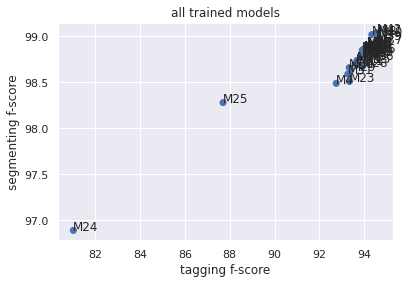

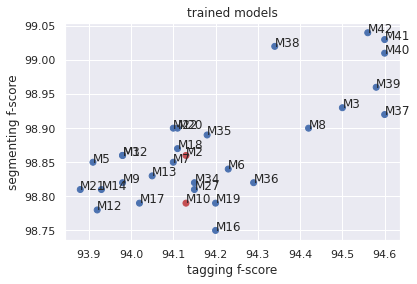

In [194]:
# plot the 2D scatter to show the hyperparameters result
# load results table
table = pd.read_csv(os.getcwd() +"/hyperparameter tuning/hyperparameter tuning.csv")

y1 = table["seg_f"]
z1 = table["tag_f"]
n1 = table["Model"] 
num = table["num"] 


filter_seg_f = table["seg_f"][table["Model"]=="M2"].iloc[0]
filter_tag_f = table["tag_f"][table["Model"]=="M2"].iloc[0]
filter_seg_s = table["seg_f"][table["Model"]=="M10"].iloc[0]
filter_tag_s = table["tag_f"][table["Model"]=="M10"].iloc[0]

y=[]
z=[]
n=[]
c=[]
c1=[]

out = []
for y2,z2,n2,nu in zip(y1,z1,n1,num):
    if(nu<10) and ((y2>filter_seg_f) or (z2>filter_tag_f)):
        out.append(n2)
    if(nu>10) and ((y2>filter_seg_s) or (z2>filter_tag_s)):
        out.append(n2)
    if not(n2 == "M24" or n2 == "M25") and z2>93.8 and y2>98.73:
        y.append(y2)
        z.append(z2)
        n.append(n2)
        if(n2 == "M10" or n2 == "M2"):
            c.append("r")
        else:
            c.append("b")
    if(n2 == "M10" or n2 == "M2"):
        c1.append("r")
    else:
        c1.append("b")

# print the models with segmentation or tagging result greater than or equal to the results of the baseline
print(out)

fig, ax = plt.subplots()
ax.scatter(z1, y1, color=c1)

for i, txt in enumerate(n1):
    ax.annotate(txt, (z1[i], y1[i]))
    
plt.title('all trained models')
plt.xlabel('tagging f-score')
plt.ylabel('segmenting f-score')

fig, ax = plt.subplots()
ax.scatter(z, y,color=c)

for i, txt in enumerate(n):
    ax.annotate(txt, (z[i], y[i]))
plt.title('trained models')
plt.xlabel('tagging f-score')
plt.ylabel('segmenting f-score')

Text(0, 0.5, 'Seg. F1')

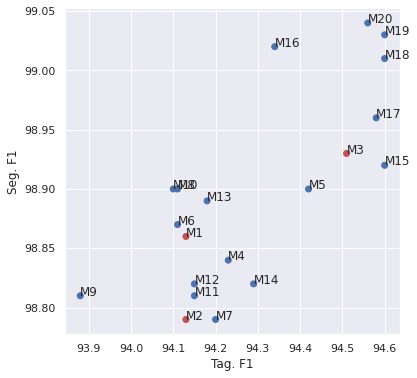

In [3]:
# plot models with a good score compared to the baselines
table = pd.read_csv(os.getcwd() +"/hyperparameter tuning/hyperparameter tuning fi.csv")

y = table["seg_f"]
z = table["tag_f"]
n = table["Model"] 
c = []

for m in n:
    if(m == "M3" or m == "M1" or m == "M2"):
        c.append("r")
    else:
        c.append("b")

fig, ax = plt.subplots(figsize=(6,6))
ax.scatter(z, y, color=c)

for i, txt in enumerate(n):
    ax.annotate(txt, (z[i], y[i]))

plt.xlabel('Tag. F1')
plt.ylabel('Seg. F1')

Text(0, 0.5, 'Seg. F1')

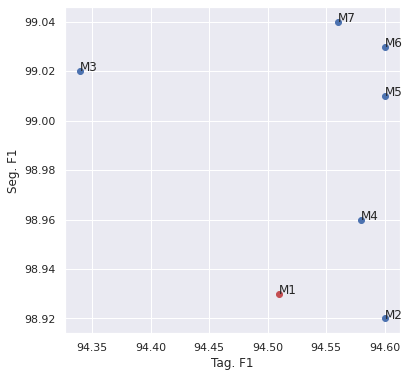

In [7]:
# plot models with a good score compared to the initial baseline
table = pd.read_csv(os.getcwd() +"/hyperparameter tuning/hyperparameter tuning fi.csv")

y = table["seg_f"]
z = table["tag_f"]
n = table["Model"] 
c = []

M3_Seg = 0
M3_Teg = 0
i=0
for m in n:
    if(m == "M3"):
        c.append("r")
        M3_Seg = y[i]
        M3_Teg = z[i]
    else:
        c.append("b")
    i+=1

fig, ax = plt.subplots(figsize=(6,6))
for i in range(len(n)):
    if(y[i] >= M3_Seg or z[i] >= M3_Teg):
        ax.scatter(z[i], y[i], color=c[i])
j=0
for i, txt in enumerate(n):
    if(y[i] >= M3_Seg or z[i] >= M3_Teg):
        j+=1
        ax.annotate("M"+str(j), (z[i], y[i]))

#plt.title('models with a good score compared to the baselines')
plt.xlabel('Tag. F1')
plt.ylabel('Seg. F1')

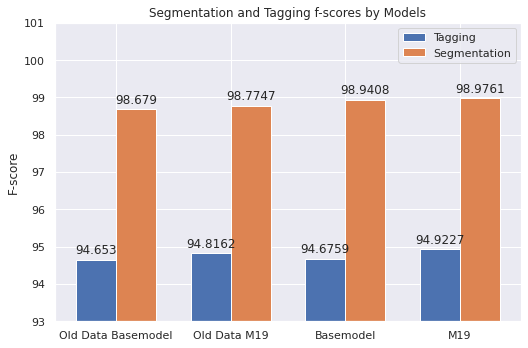

In [197]:
# plot the bar chart to compare the results of the model that trained on 20,000 old data and 30,000 new data
labels = ['Old Data Basemodel', 'Old Data M19', 'Basemodel', 'M19']
tags_fscore = [94.653, 94.8162, 94.6759, 94.9227]
seg_fscore = [98.679, 98.7747, 98.9408, 98.9761]

x = np.arange(len(labels))  
width = 0.35  

fig, ax = plt.subplots(figsize=(7.5,5))
rects1 = ax.bar(x - width/2, tags_fscore, width, label='Tagging')
rects2 = ax.bar(x + width/2, seg_fscore, width, label='Segmentation')


ax.set_ylabel('F-score')
ax.set_title('Segmentation and Tagging f-scores by Models')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.legend()

axes = plt.gca()
axes.set_ylim([93,101])

ylim = axes.get_ylim()
factor = 0.001
new_ylim = (ylim[0] + ylim[1])/2 + np.array((-0.5, 0.5)) * (ylim[1] - ylim[0]) * (1 + factor) 
axes.set_ylim(new_ylim)

def autolabel(rects):
    """Attach a text label above each bar in *rects*, displaying its height."""
    for rect in rects:
        height = rect.get_height()
        ax.annotate('{}'.format(height),
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3), 
                    textcoords="offset points",
                    ha='center', va='bottom')


autolabel(rects1)
autolabel(rects2)

fig.tight_layout()

plt.show()
